# Netflix Movies & TV Shows Clustering Using Unsupervised Machine Learning
### Exploratory Data Analysis, NLP-Based Feature Engineering and Unsupervised Content Clustering

**Project type:** Unsupervised Machine Learning · EDA · NLP/Text Mining · Clustering · Business Analytics  
**Primary question:** Can Netflix titles be grouped into useful content segments using text and content metadata?

This notebook is organized into the seven required project stages. It uses the supplied CSV and the project brief/deck. The brief describes a 2019 catalog snapshot, while the supplied CSV contains `date_added` values later than 2019; analyses therefore describe the supplied file as provided and flag that scope mismatch. No source rows are silently removed for having incomplete metadata.


## Stage 1 — Data Cleaning & Preparation

We first inspect the real file and schema. Cleaning decisions are evidence-based and preserve incomplete but potentially informative titles.

### 1. Project setup and reproducibility

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")  # Saved project figures render identically in Colab and local Jupyter.
from IPython.display import display, Markdown, Image

_cwd = Path.cwd()
_candidates = [_cwd, _cwd.parent, _cwd / "netflix-unsupervised-ml", _cwd.parent / "netflix-unsupervised-ml"]
PROJECT_ROOT = next((p.resolve() for p in _candidates if (p / "src").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the project root or notebooks folder.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data_loading import load_titles
from data_cleaning import inspect_schema, clean_titles
from eda import run_eda
from hypothesis_testing import run_hypothesis_tests
from feature_engineering import make_text_features, add_metadata_features
from preprocessing import vectorize_text
from model_runner import run_models

RAW_PATH = PROJECT_ROOT / "data/raw/netflix_titles.csv"
PROCESSED_PATH = PROJECT_ROOT / "data/processed/netflix_titles_cleaned.csv"
FIGURES = PROJECT_ROOT / "outputs/figures"
TABLES = PROJECT_ROOT / "outputs/tables"
MODELS = PROJECT_ROOT / "outputs/models"
for folder in [FIGURES, TABLES, MODELS, PROCESSED_PATH.parent]:
    folder.mkdir(parents=True, exist_ok=True)

raw_df = load_titles(RAW_PATH)
print(f"Loaded {RAW_PATH.name} | shape={raw_df.shape}")

Loaded netflix_titles.csv | shape=(7787, 12)


### 2. Required schema inspection

In [2]:
schema = inspect_schema(raw_df)
print("Shape:", schema["shape"])
print("Columns:", schema["columns"])
display(raw_df.head())
display(raw_df.tail())
inspection = pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "missing_count": raw_df.isna().sum(),
    "missing_pct": (raw_df.isna().mean() * 100).round(2),
    "unique_values": raw_df.nunique(dropna=False),
}).sort_index()
display(inspection)
print("Exact duplicate rows:", int(raw_df.duplicated().sum()))
print("Numeric columns:", raw_df.select_dtypes(include="number").columns.tolist())
print("String columns:", raw_df.select_dtypes(include=["str", "object"]).columns.tolist())
print("Low-cardinality unique values:")
for col in raw_df.columns:
    if raw_df[col].nunique(dropna=False) <= 20:
        print(f"  {col}: {raw_df[col].dropna().unique().tolist()}")
    else:
        print(f"  {col}: {raw_df[col].nunique(dropna=False):,} unique; sample={raw_df[col].dropna().head(3).tolist()}")

Shape: (7787, 12)
Columns: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
7782,s7783,Movie,Zozo,Josef Fares,"Imad Creidi, Antoinette Turk, Elias Gergi, Car...","Sweden, Czech Republic, United Kingdom, Denmar...","October 19, 2020",2005,TV-MA,99 min,"Dramas, International Movies",When Lebanon's Civil War deprives Zozo of his ...
7783,s7784,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...
7784,s7785,Movie,Zulu Man in Japan,NaN,Nasty C,NaN,"September 25, 2020",2019,TV-MA,44 min,"Documentaries, International Movies, Music & M...","In this documentary, South African rapper Nast..."
7785,s7786,TV Show,Zumbo's Just Desserts,NaN,"Adriano Zumbo, Rachel Khoo",Australia,"October 31, 2020",2019,TV-PG,1 Season,"International TV Shows, Reality TV",Dessert wizard Adriano Zumbo looks for the nex...
7786,s7787,Movie,ZZ TOP: THAT LITTLE OL' BAND FROM TEXAS,Sam Dunn,NaN,"United Kingdom, Canada, United States","March 1, 2020",2019,TV-MA,90 min,"Documentaries, Music & Musicals",This documentary delves into the mystique behi...


,dtype,missing_count,missing_pct,unique_values
cast,str,718,9.22,6832
country,str,507,6.51,682
date_added,str,10,0.13,1566
description,str,0,0.00,7769
director,str,2389,30.68,4050
duration,str,0,0.00,216
listed_in,str,0,0.00,492
rating,str,7,0.09,15
release_year,int64,0,0.00,73
show_id,str,0,0.00,7787


Exact duplicate rows: 0
Numeric columns: ['release_year']
String columns: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'rating', 'duration', 'listed_in', 'description']
Low-cardinality unique values:
  show_id: 7,787 unique; sample=['s1', 's2', 's3']
  type: ['TV Show', 'Movie']
  title: 7,787 unique; sample=['3%', '7:19', '23:59']
  director: 4,050 unique; sample=['Jorge Michel Grau', 'Gilbert Chan', 'Shane Acker']
  cast: 6,832 unique; sample=['João Miguel, Bianca Comparato, Michel Gomes, Rodolfo Valente, Vaneza Oliveira, Rafael Lozano, Viviane Porto, Mel Fronckowiak, Sergio Mamberti, Zezé Motta, Celso Frateschi', 'Demián Bichir, Héctor Bonilla, Oscar Serrano, Azalia Ortiz, Octavio Michel, Carmen Beato', 'Tedd Chan, Stella Chung, Henley Hii, Lawrence Koh, Tommy Kuan, Josh Lai, Mark Lee, Susan Leong, Benjamin Lim']
  country: 682 unique; sample=['Brazil', 'Mexico', 'Singapore']
  date_added: 1,566 unique; sample=['August 14, 2020', 'December 23, 2016', 'De

### 3. Data dictionary from the observed schema

In [3]:
data_dictionary = pd.read_csv(TABLES / "data_dictionary.csv")
display(data_dictionary)
print("All values are stored as strings except release_year in this CSV. Duration is a mixed-unit string (minutes for Movies, seasons for TV Shows).")

,column,meaning_from_schema,analytical_type
0,show_id,Unique record identifier; not a model feature,identifier
1,type,Movie or TV Show content format,categorical
2,title,Title of the work,text
3,director,Listed director(s); missing in many rows,multi-value metadata
4,cast,Listed cast members,multi-value metadata
5,country,Country/countries credited on the title,multi-value metadata
6,date_added,Date added to Netflix as supplied; parseable date,date-like
7,release_year,Original release year,numeric/temporal
8,rating,Content rating label,categorical
9,duration,Mixed unit string: movie minutes or TV seasons,mixed-unit text


All values are stored as strings except release_year in this CSV. Duration is a mixed-unit string (minutes for Movies, seasons for TV Shows).


### 4. Missing values, duplicates, and conservative cleaning decisions

| Field(s) | Observed issue | Decision | Reason |
|---|---:|---|---|
| `director` | substantial missingness | Preserve missing | Director may not be supplied; filling a fabricated name adds false evidence. Empty text is used only in vector construction. |
| `cast`, `country` | missing metadata | Preserve; display as `Unknown` only in summaries where useful | Missing credits/country attribution do not make the title unusable. |
| `date_added`, `rating` | a small number missing | Preserve in source; date analyses omit only rows without a usable date, ratings display an Unknown bucket | Avoid inventing dates or rating categories. |
| `description`, `duration`, `title`, `listed_in` | complete in supplied file | Retain | These are valuable content fields. |
| exact duplicate rows | checked below | Remove exact duplicates only, if any | Near-duplicate or similar titles can be legitimate distinct records. |
| string whitespace | inconsistent edge/repeated whitespace | Strip ends and normalize repeated whitespace; preserve capitalization and meaningful punctuation in source columns | Conservative text normalization; lowercase is applied only to the NLP copy. |

The `show_id` field is an identifier, not a clustering feature. Release-year extremes and short/long durations are reviewed as possible legitimate cases, not dropped by a generic outlier rule.


In [4]:
clean_df, cleaning_impact = clean_titles(raw_df)
clean_df.to_csv(PROCESSED_PATH, index=False)
cleaning_impact.to_csv(TABLES / "cleaning_impact.csv")
display(cleaning_impact)
print(f"Before: {raw_df.shape}; after: {clean_df.shape}; exact duplicates after cleaning: {clean_df.duplicated().sum()}")
print("Missing counts retained:")
display(clean_df.isna().sum().to_frame("missing_after_cleaning"))
print("Invalid content types:", sorted(set(clean_df["type"].dropna()) - {"Movie", "TV Show"}))
movie_unit_errors = int((clean_df["type"].eq("Movie") & ~clean_df["duration"].str.endswith("min")).sum())
tv_unit_errors = int((clean_df["type"].eq("TV Show") & ~clean_df["duration"].str.contains("Season", case=False)).sum())
print("Duration-unit mismatches — Movie:", movie_unit_errors, "TV Show:", tv_unit_errors)

,missing_before,missing_after,missing_pct_before,missing_pct_after,whitespace_normalized_cells
cast,718,718,9.22,9.22,5.0
country,507,507,6.51,6.51,0.0
date_added,10,10,0.13,0.13,88.0
description,0,0,0.00,0.00,15.0
director,2389,2389,30.68,30.68,0.0
duration,0,0,0.00,0.00,0.0
listed_in,0,0,0.00,0.00,0.0
rating,7,7,0.09,0.09,0.0
release_year,0,0,0.00,0.00,NaN
show_id,0,0,0.00,0.00,0.0


Before: (7787, 12); after: (7787, 12); exact duplicates after cleaning: 0
Missing counts retained:


,missing_after_cleaning
show_id,0
type,0
title,0
director,2389
cast,718
country,507
date_added,10
release_year,0
rating,7
duration,0


Invalid content types: []
Duration-unit mismatches — Movie: 0 TV Show: 0


## Stage 2 — Exploratory Data Analysis (EDA)

All charts are generated from the cleaned supplied dataset and saved under `outputs/figures/`. Each interpretation is printed with the chart.

In [5]:
eda_results = run_eda(clean_df, FIGURES, TABLES)
type_counts = clean_df["type"].value_counts()
added = pd.to_datetime(clean_df["date_added"], errors="coerce")
added_type = pd.read_csv(TABLES / "titles_added_by_year_and_type.csv", index_col=0)
display(type_counts.rename("titles").to_frame())
print("Added-date range:", added.min(), "to", added.max())

,titles
type,
Movie,5377
TV Show,2410


Added-date range: 2008-01-01 00:00:00 to 2021-01-16 00:00:00


### 5. Movies vs TV Shows

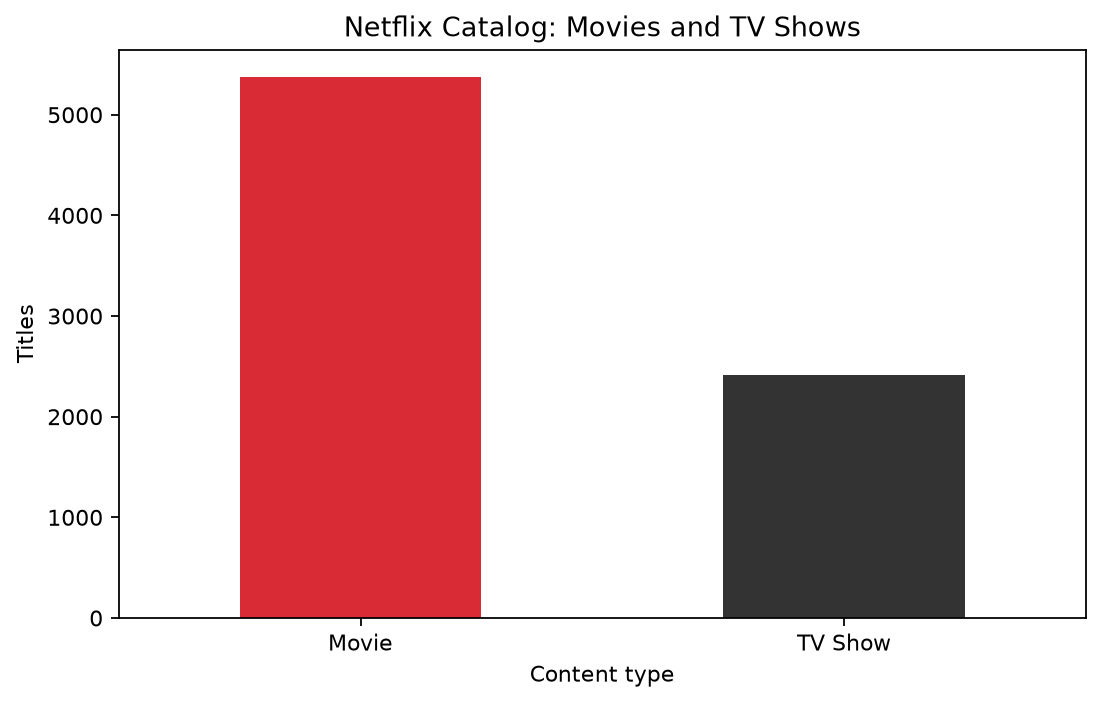

**INSIGHT:** The supplied file contains 5,377 Movies and 2,410 TV Shows. Movies are 69.1% of these rows. This is a catalog composition snapshot, not by itself evidence of a change over time.

**BUSINESS RELEVANCE:** Catalog mix can inform how stakeholders organize title discovery and compare formats, while trend claims require date-aware analysis.

In [6]:
display(Image(filename=str(FIGURES / "content_type_distribution.png")))
movie_n, tv_n = int(type_counts.get("Movie", 0)), int(type_counts.get("TV Show", 0))
display(Markdown(f"**INSIGHT:** The supplied file contains {movie_n:,} Movies and {tv_n:,} TV Shows. Movies are {movie_n/(movie_n+tv_n):.1%} of these rows. This is a catalog composition snapshot, not by itself evidence of a change over time.\n\n**BUSINESS RELEVANCE:** Catalog mix can inform how stakeholders organize title discovery and compare formats, while trend claims require date-aware analysis."))

### 6. Content added over time

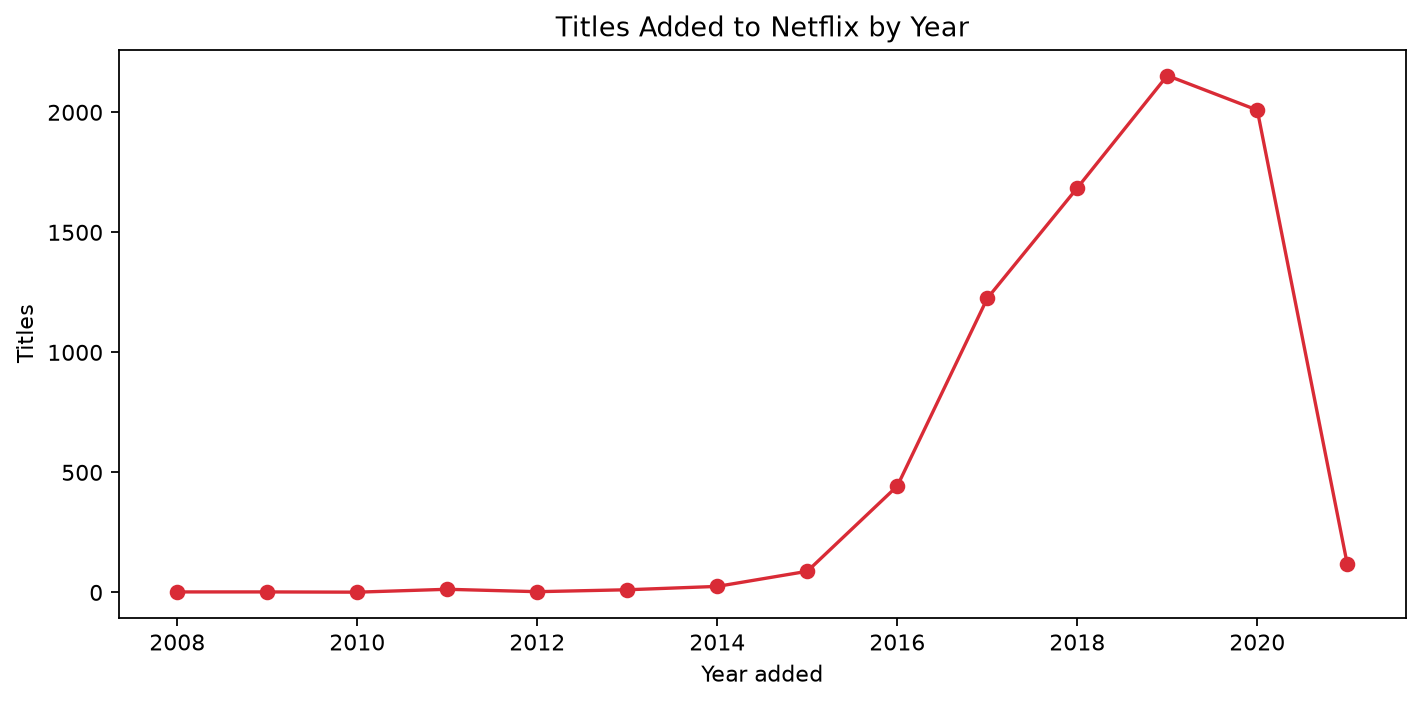

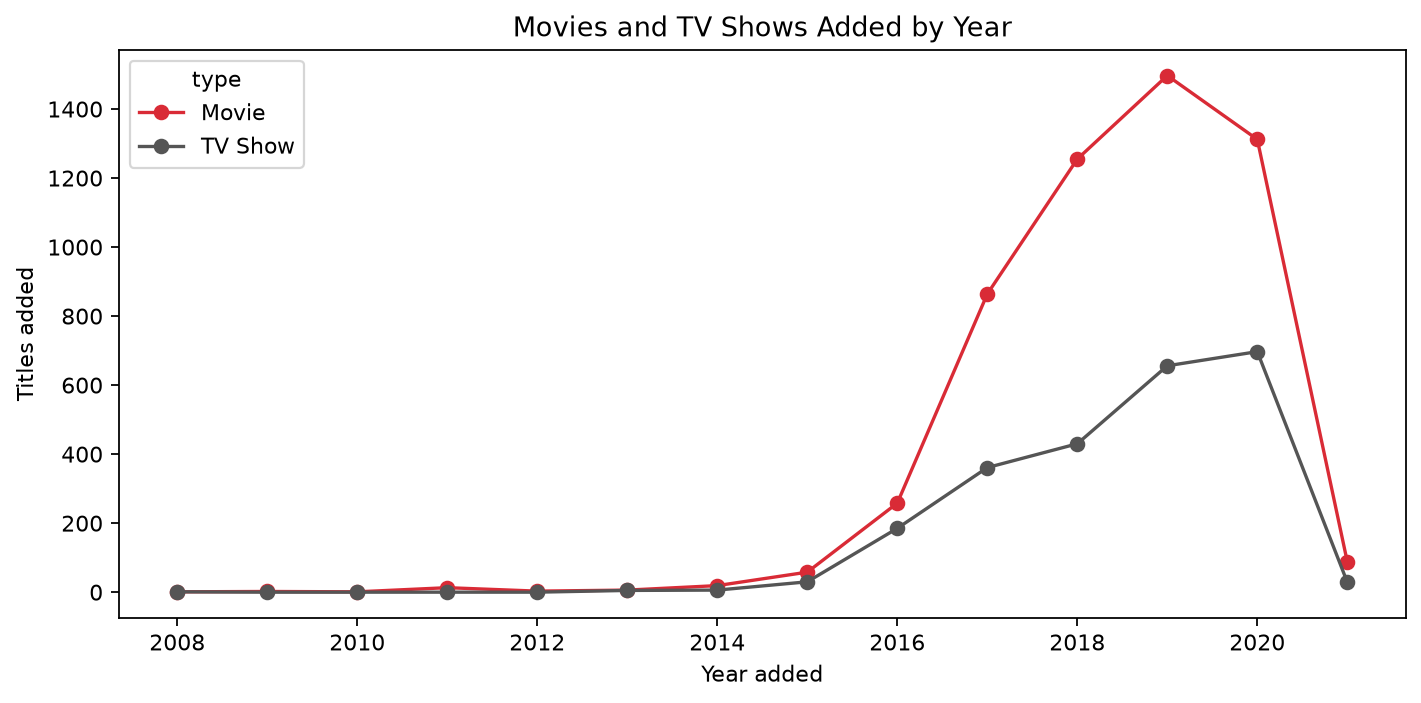

**INSIGHT:** The supplied file records additions from 2008-01-01 through 2021-01-16; the largest recorded year is 2019 (2,153 rows). These counts are based on this file's `date_added` values.

**BUSINESS RELEVANCE:** Addition patterns can help frame catalog-planning questions. This retrospective file cannot establish commissioning intent or explain removals.

In [7]:
display(Image(filename=str(FIGURES / "titles_added_by_year.png")))
display(Image(filename=str(FIGURES / "titles_added_by_year_and_type.png")))
year_totals = added.dt.year.value_counts().sort_index()
peak_year = int(year_totals.idxmax())
display(Markdown(f"**INSIGHT:** The supplied file records additions from {added.min():%Y-%m-%d} through {added.max():%Y-%m-%d}; the largest recorded year is {peak_year} ({int(year_totals.max()):,} rows). These counts are based on this file's `date_added` values.\n\n**BUSINESS RELEVANCE:** Addition patterns can help frame catalog-planning questions. This retrospective file cannot establish commissioning intent or explain removals."))

### 7. Release year and content type

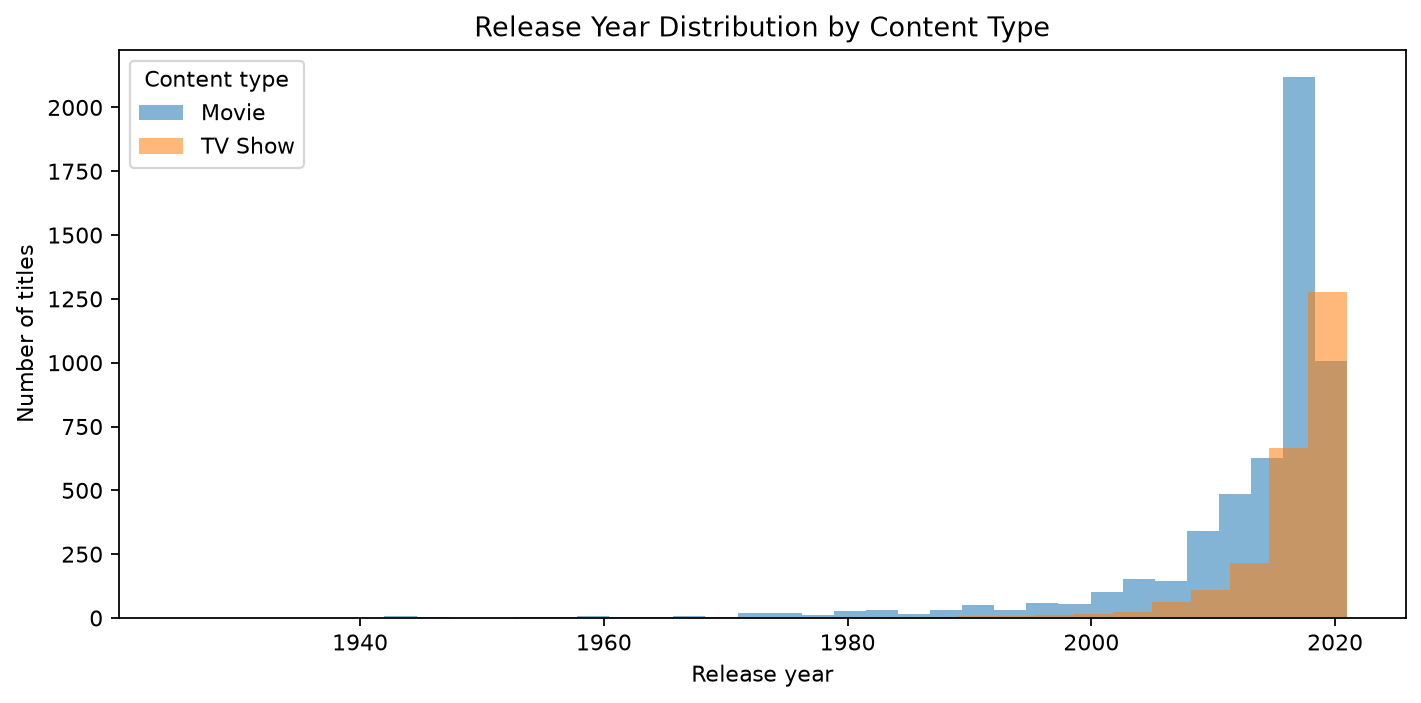

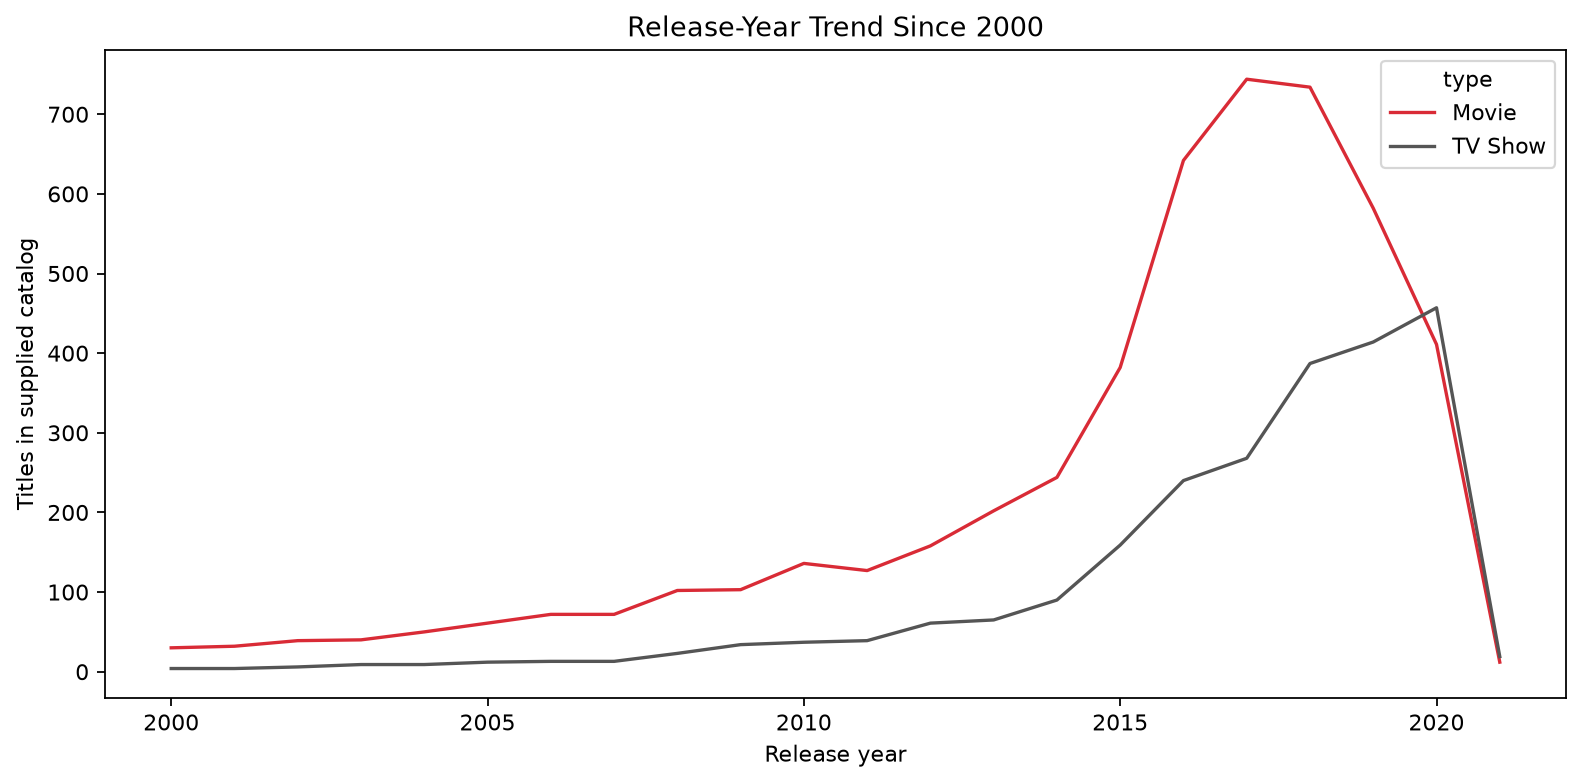

**INSIGHT:** Release years in the file range from 1925 to 2021; 51 titles predate 1970. Older entries are retained for review.

**BUSINESS RELEVANCE:** A broad release-year mix can matter when stakeholders plan catalog organization across newer releases and library titles.

In [8]:
display(Image(filename=str(FIGURES / "release_year_distribution.png")))
display(Image(filename=str(FIGURES / "release_year_by_content_type.png")))
display(Markdown(f"**INSIGHT:** Release years in the file range from {clean_df.release_year.min()} to {clean_df.release_year.max()}; {int((clean_df.release_year < 1970).sum())} titles predate 1970. Older entries are retained for review.\n\n**BUSINESS RELEVANCE:** A broad release-year mix can matter when stakeholders plan catalog organization across newer releases and library titles."))

### 8. Ratings and content type

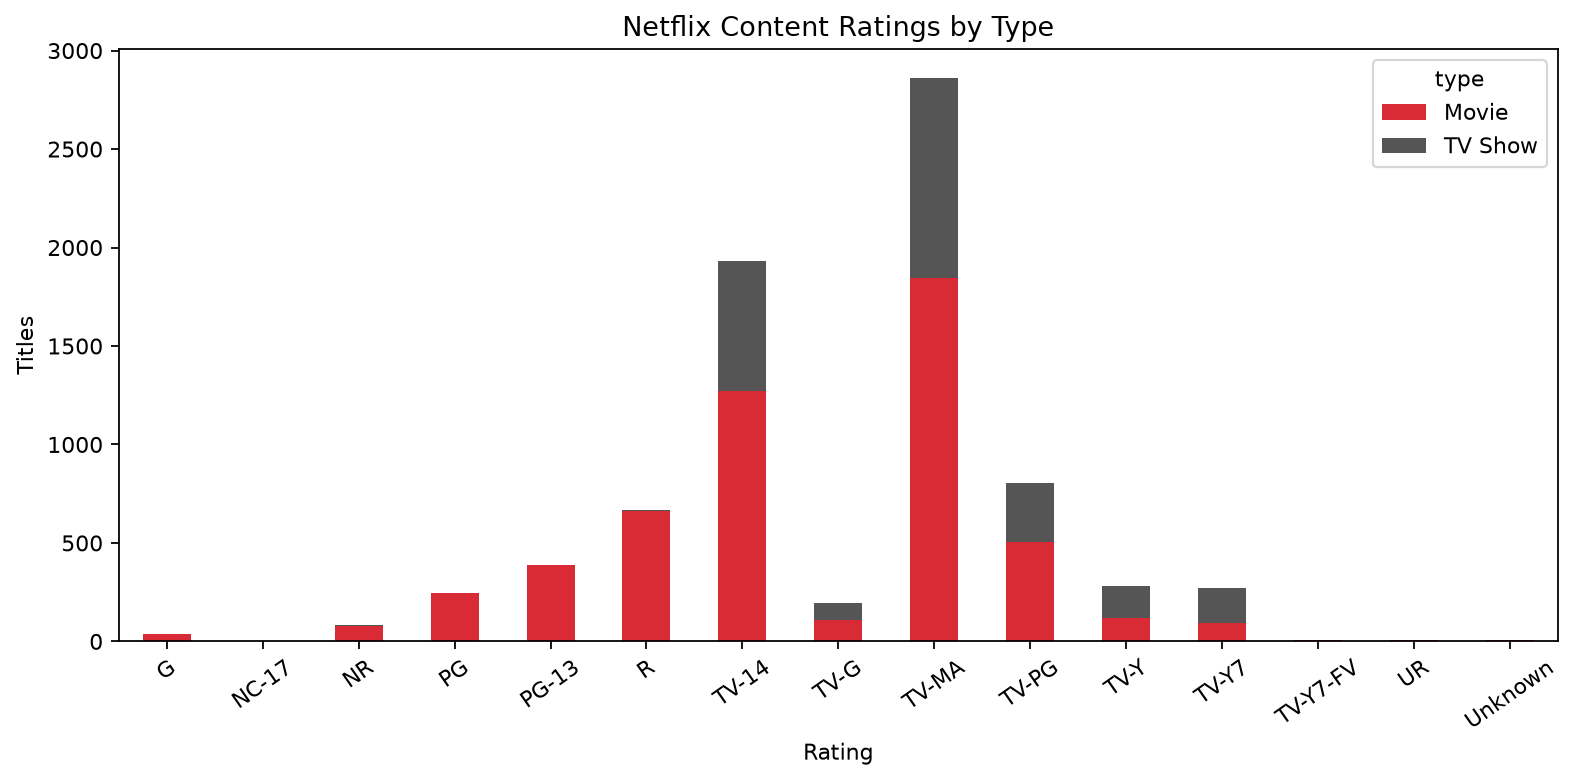

,titles
rating,
TV-MA,2863
TV-14,1931
TV-PG,806
R,665
PG-13,386
TV-Y,280
TV-Y7,271
PG,247
TV-G,194


**INSIGHT:** The most frequent rating label in the supplied catalog is **TV-MA** (2,863 rows, including any Unknown bucket if applicable).

**BUSINESS RELEVANCE:** Rating mix can support age-appropriate catalog filters and content portfolio summaries. It is not a measure of audience response.

In [9]:
display(Image(filename=str(FIGURES / "rating_distribution.png")))
rating_counts = clean_df["rating"].fillna("Unknown").value_counts()
display(rating_counts.head(10).to_frame("titles"))
display(Markdown(f"**INSIGHT:** The most frequent rating label in the supplied catalog is **{rating_counts.index[0]}** ({int(rating_counts.iloc[0]):,} rows, including any Unknown bucket if applicable).\n\n**BUSINESS RELEVANCE:** Rating mix can support age-appropriate catalog filters and content portfolio summaries. It is not a measure of audience response."))

### 9. Country distribution and country vs content type

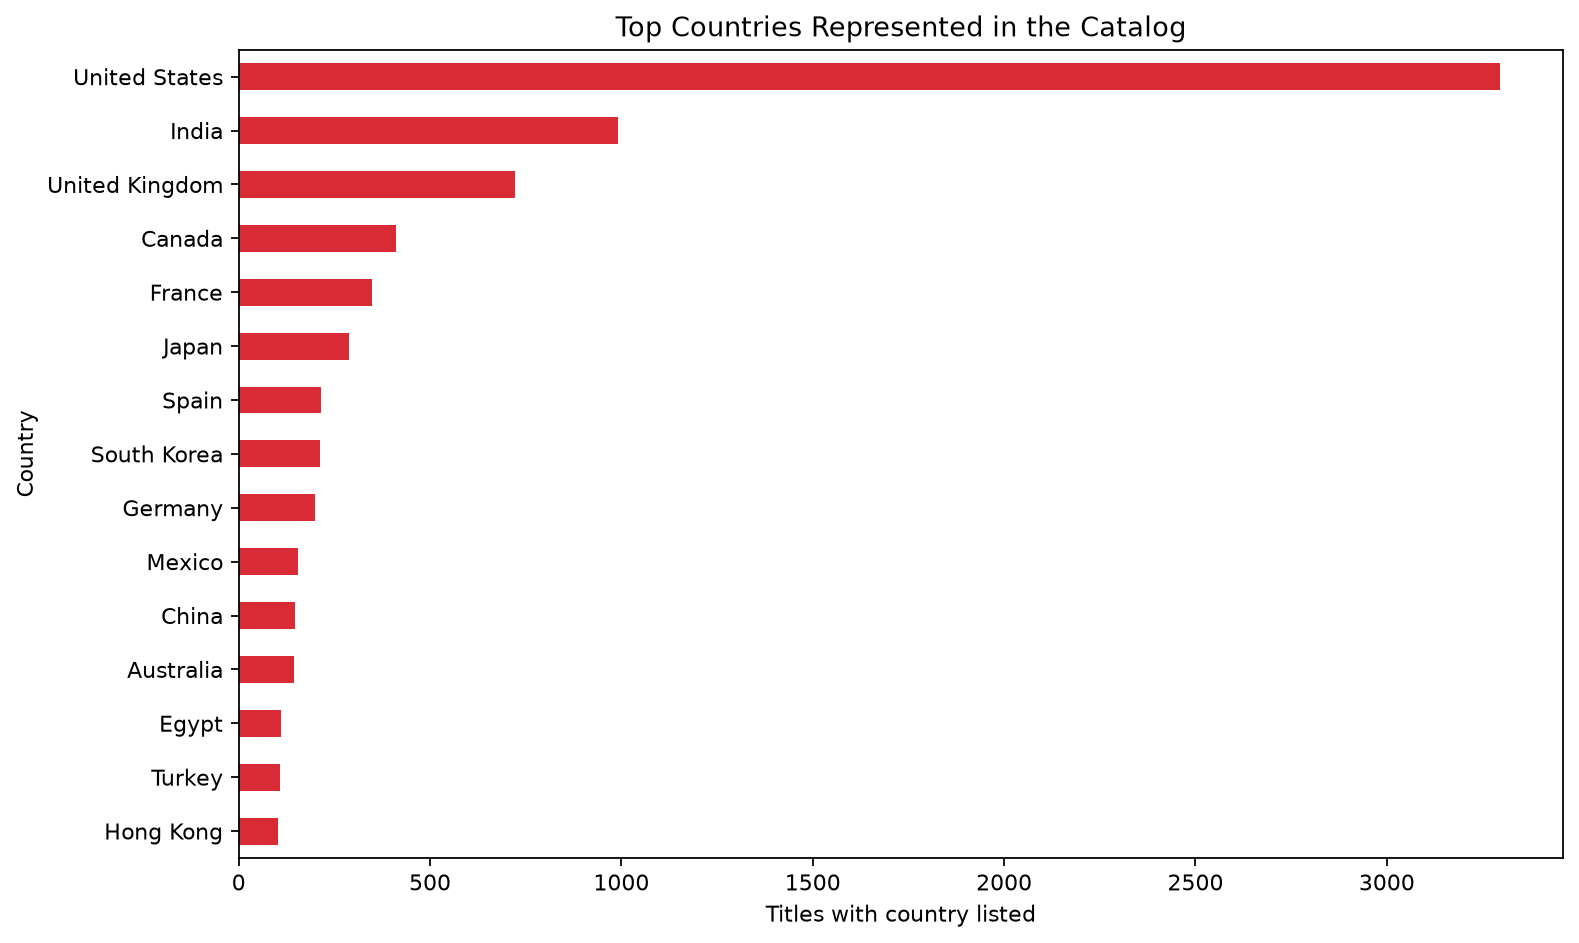

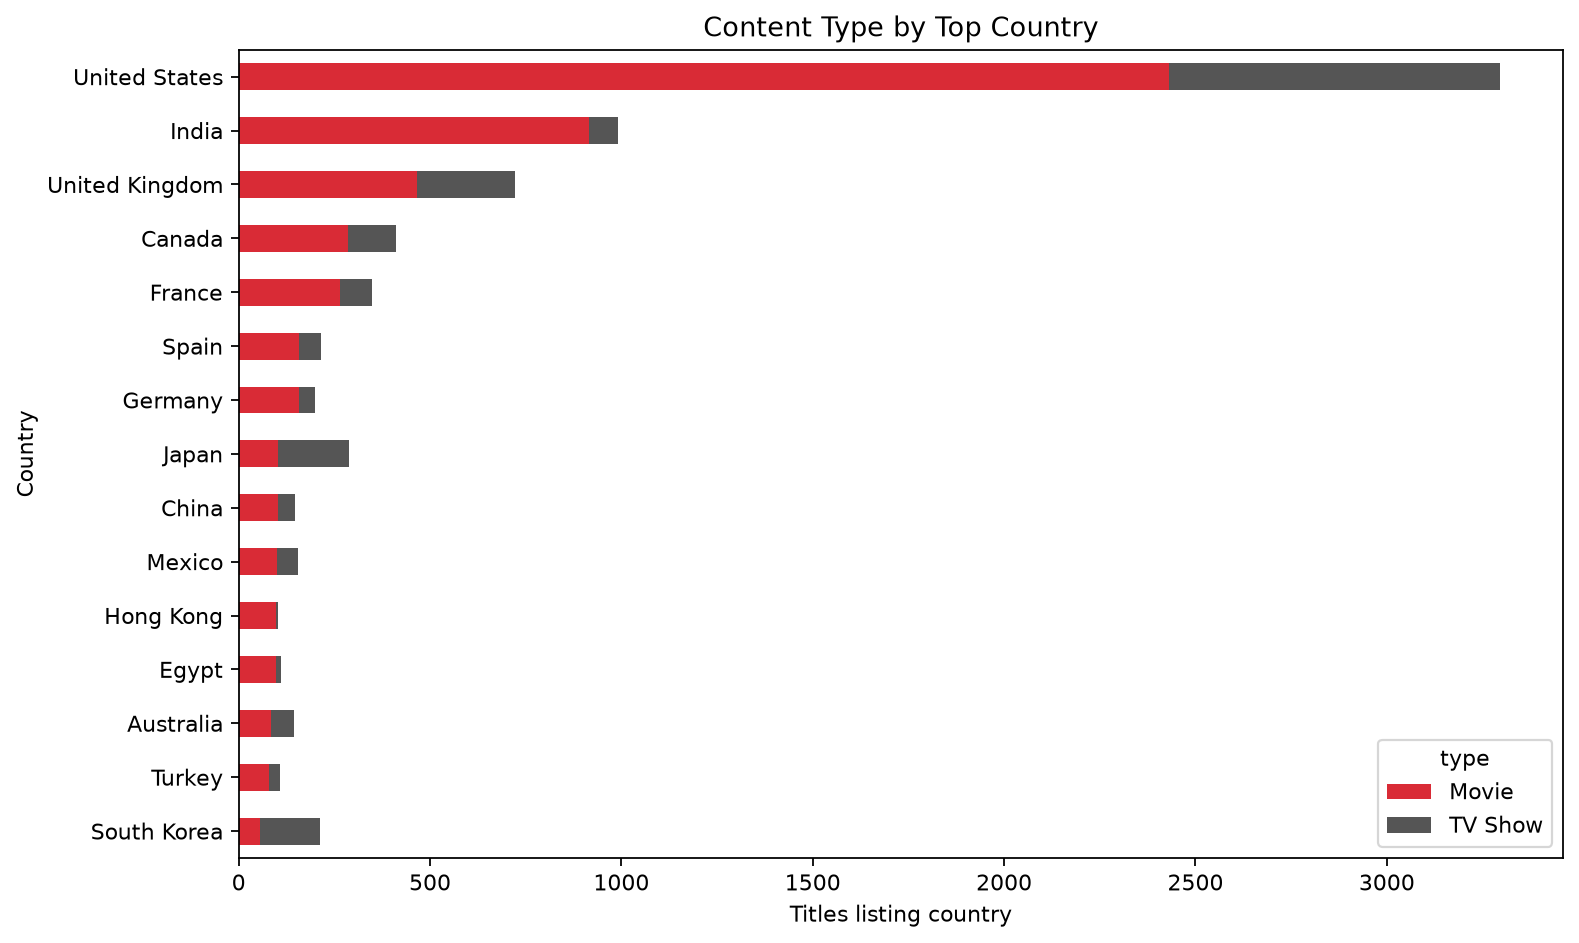

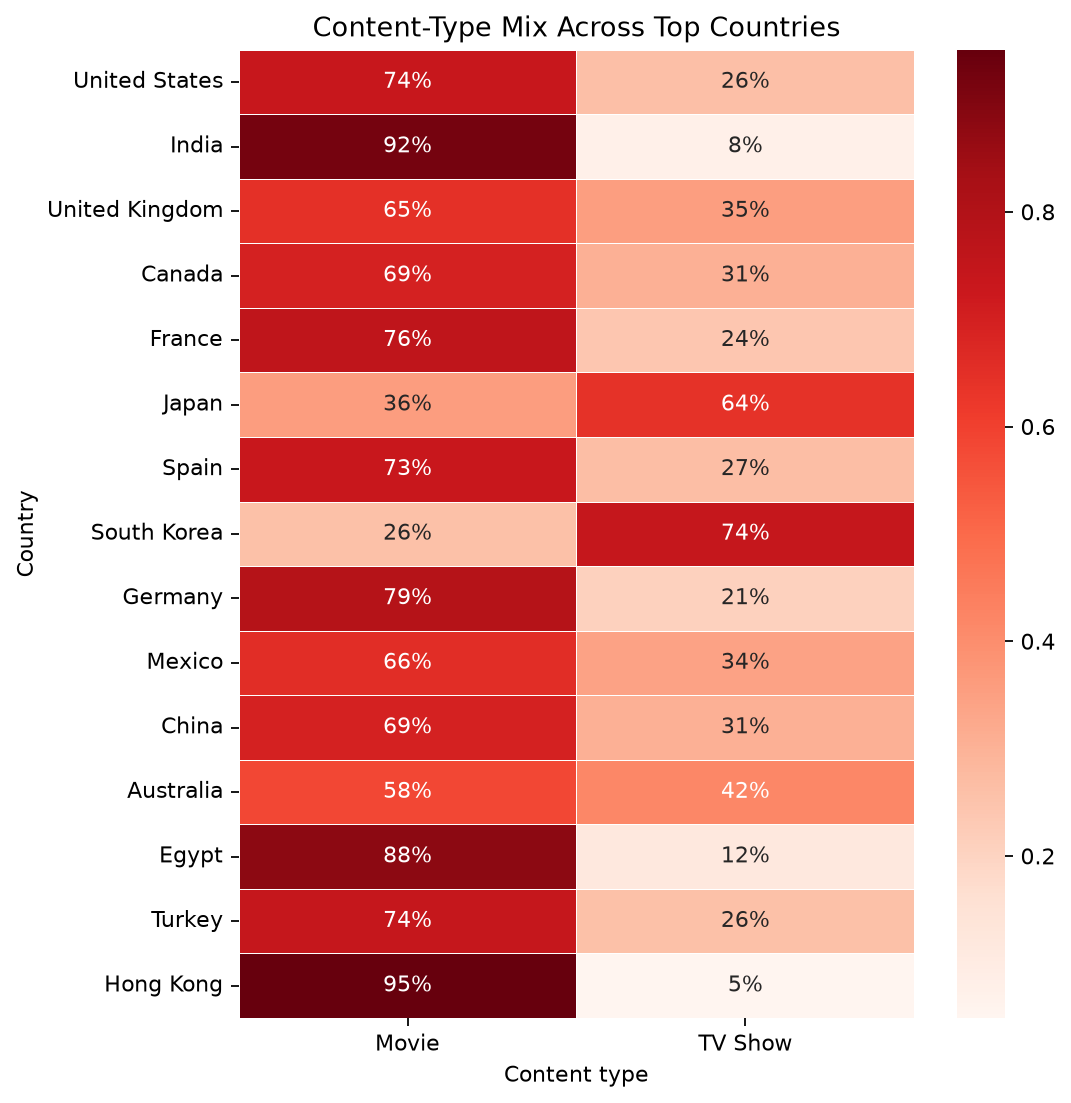

**INSIGHT:** The most frequently listed country mention is **United States** (3,296 title mentions). Titles can list multiple countries, so these are mentions and need not sum to the number of rows. The heatmap compares observed type mix across the most represented countries.

**BUSINESS RELEVANCE:** Regional catalog views can guide further market analysis. Multi-country credits and missing country metadata limit country-level comparisons.

In [10]:
display(Image(filename=str(FIGURES / "country_distribution.png")))
display(Image(filename=str(FIGURES / "country_by_content_type.png")))
display(Image(filename=str(FIGURES / "country_type_heatmap.png")))
country_top = pd.read_csv(TABLES / "top_country.csv").iloc[0]
display(Markdown(f"**INSIGHT:** The most frequently listed country mention is **{country_top['country']}** ({int(country_top['title_mentions']):,} title mentions). Titles can list multiple countries, so these are mentions and need not sum to the number of rows. The heatmap compares observed type mix across the most represented countries.\n\n**BUSINESS RELEVANCE:** Regional catalog views can guide further market analysis. Multi-country credits and missing country metadata limit country-level comparisons."))

### 10. Genre/category distribution

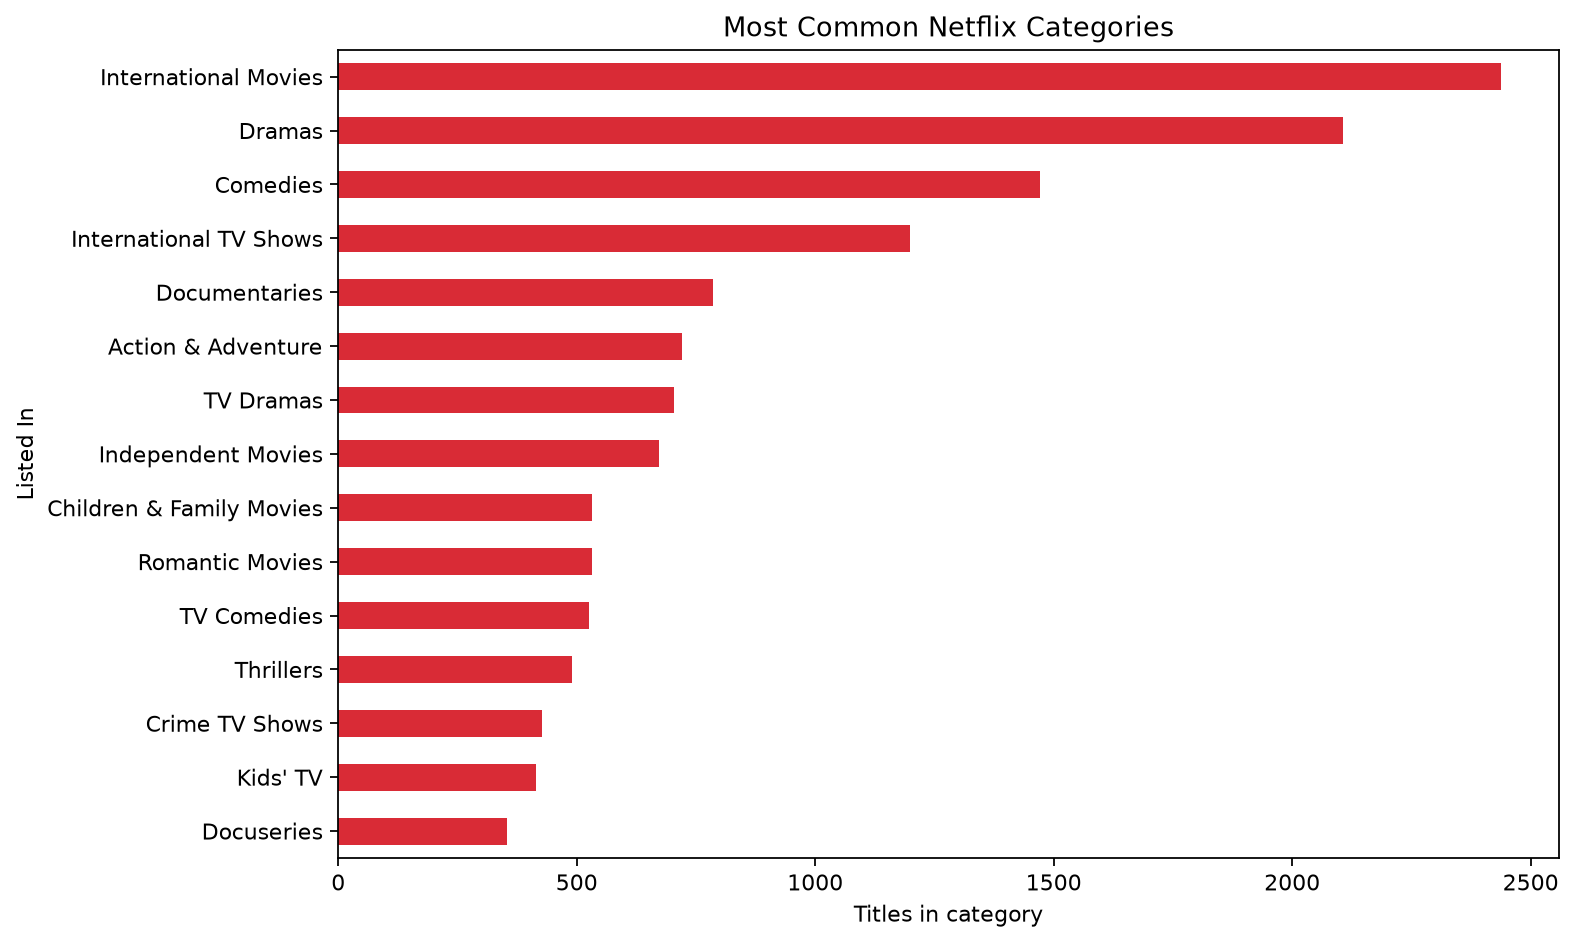

**INSIGHT:** The most common listed category is **International Movies** (2,437 title mentions). `listed_in` is multi-label, so one title may contribute to several categories.

**BUSINESS RELEVANCE:** Multi-label categories can make catalog navigation and segment-level content analysis more useful.

In [11]:
display(Image(filename=str(FIGURES / "genre_distribution.png")))
genre_top = pd.read_csv(TABLES / "top_listed_in.csv").iloc[0]
display(Markdown(f"**INSIGHT:** The most common listed category is **{genre_top['listed_in']}** ({int(genre_top['title_mentions']):,} title mentions). `listed_in` is multi-label, so one title may contribute to several categories.\n\n**BUSINESS RELEVANCE:** Multi-label categories can make catalog navigation and segment-level content analysis more useful."))

### 11. Duration, directors, and cast

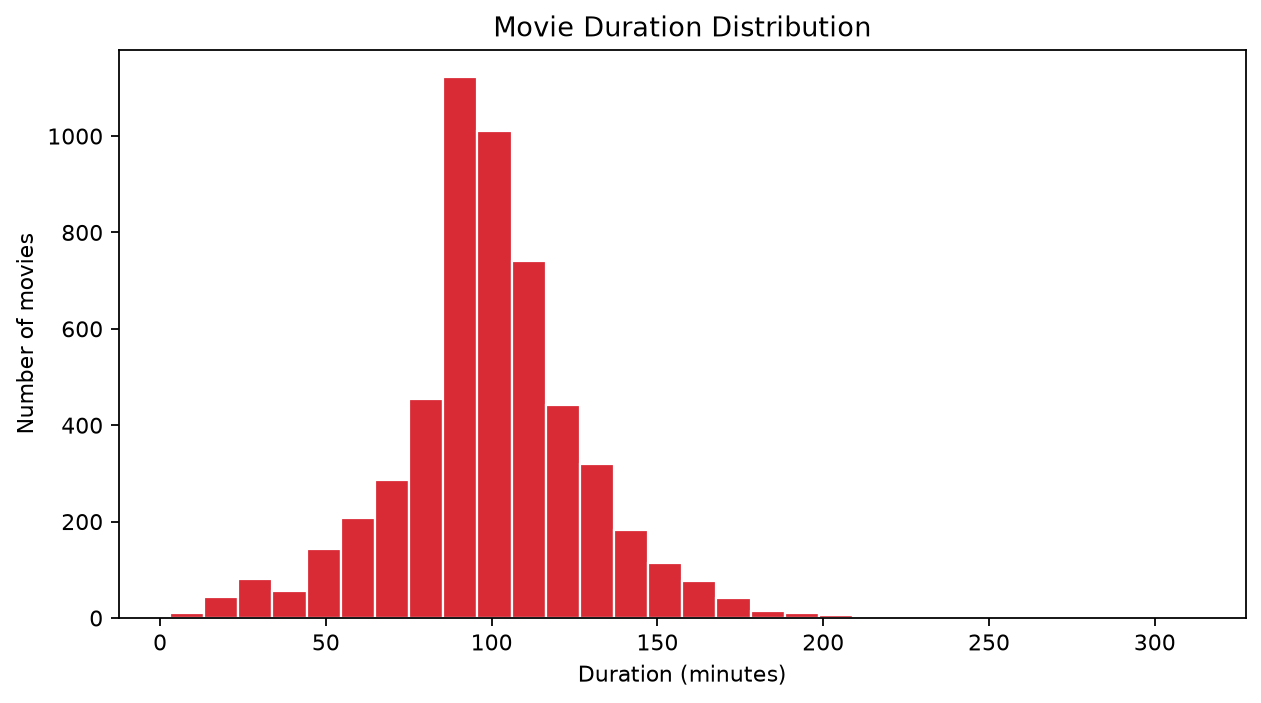

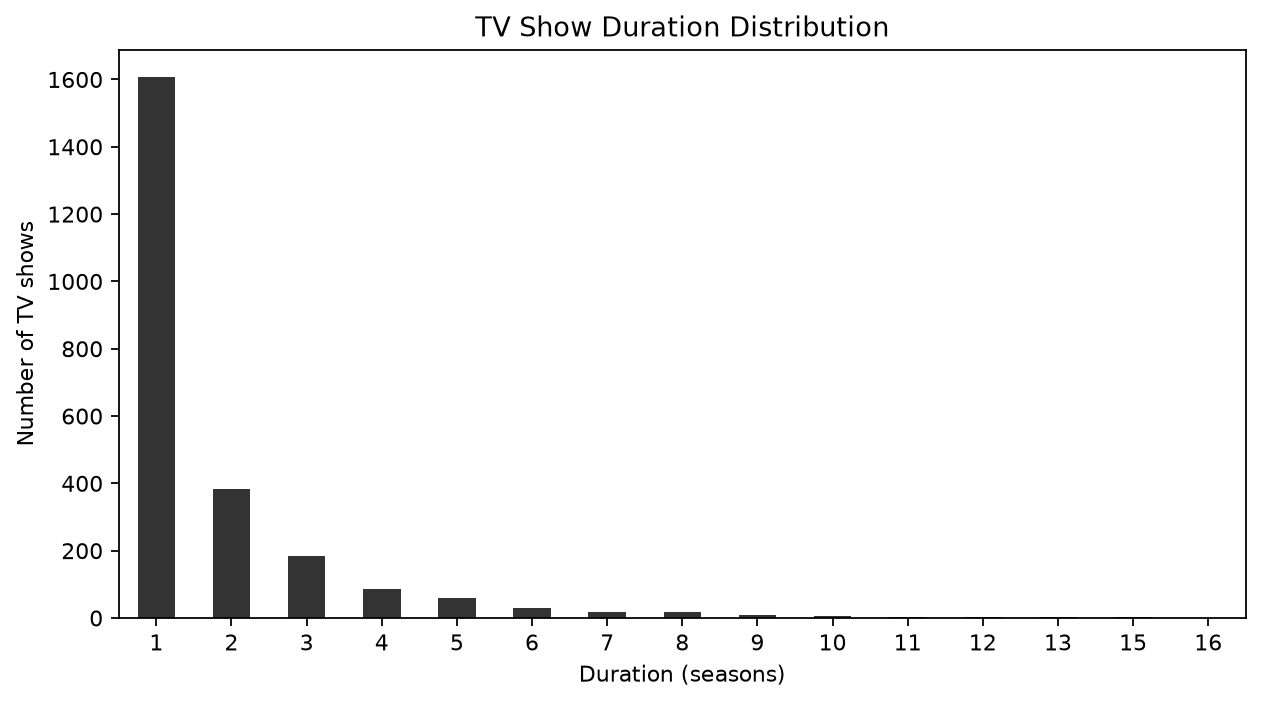

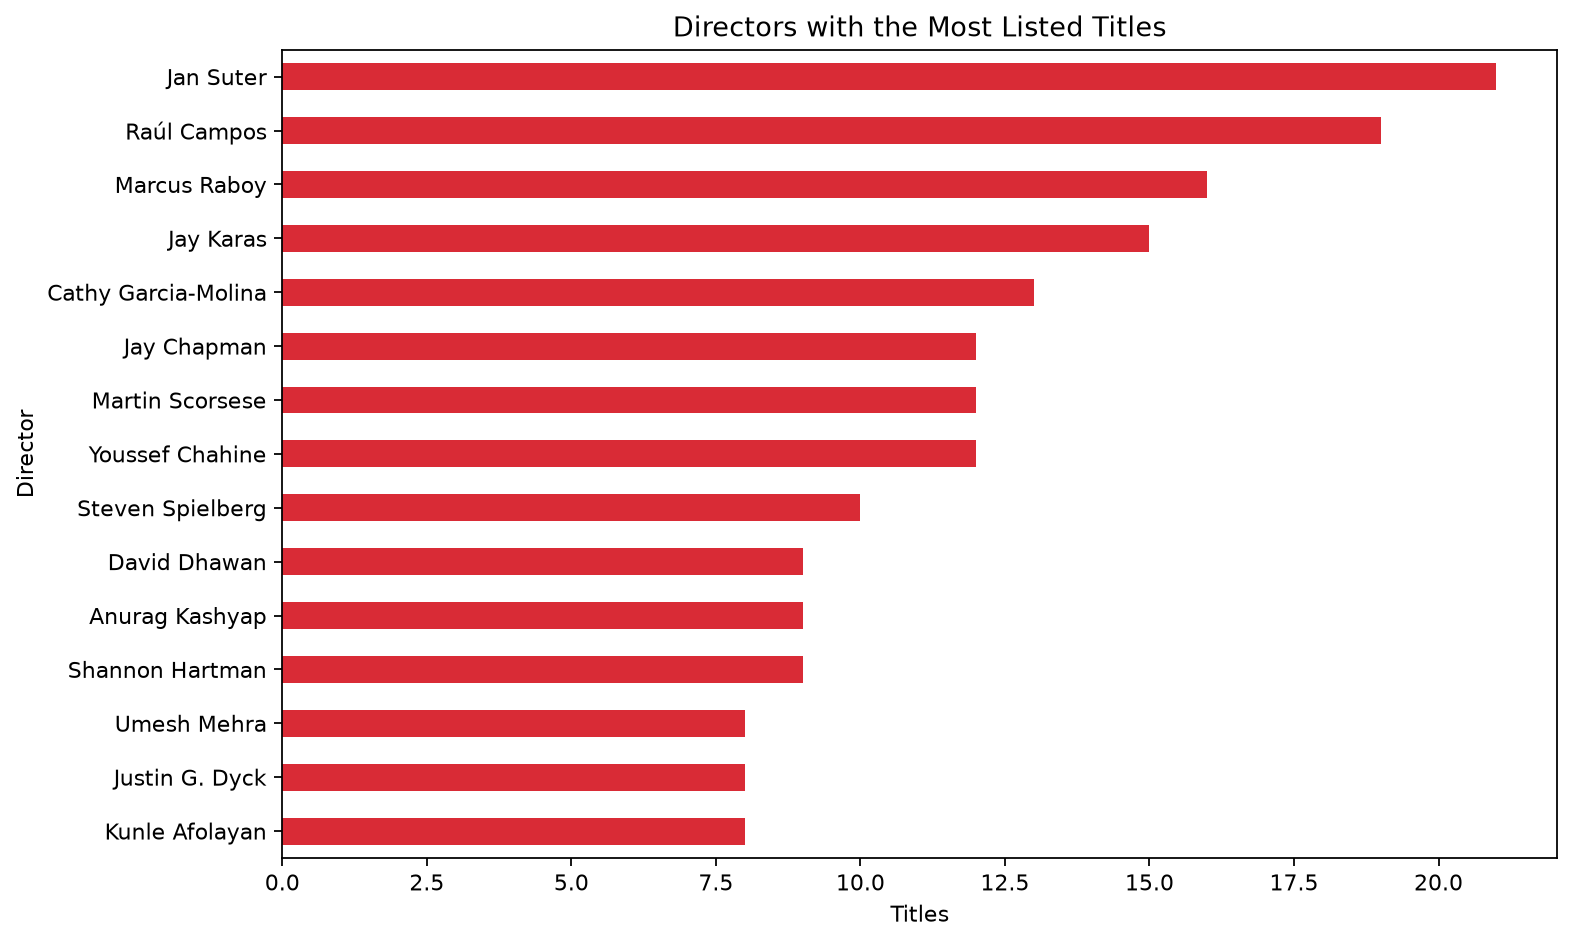

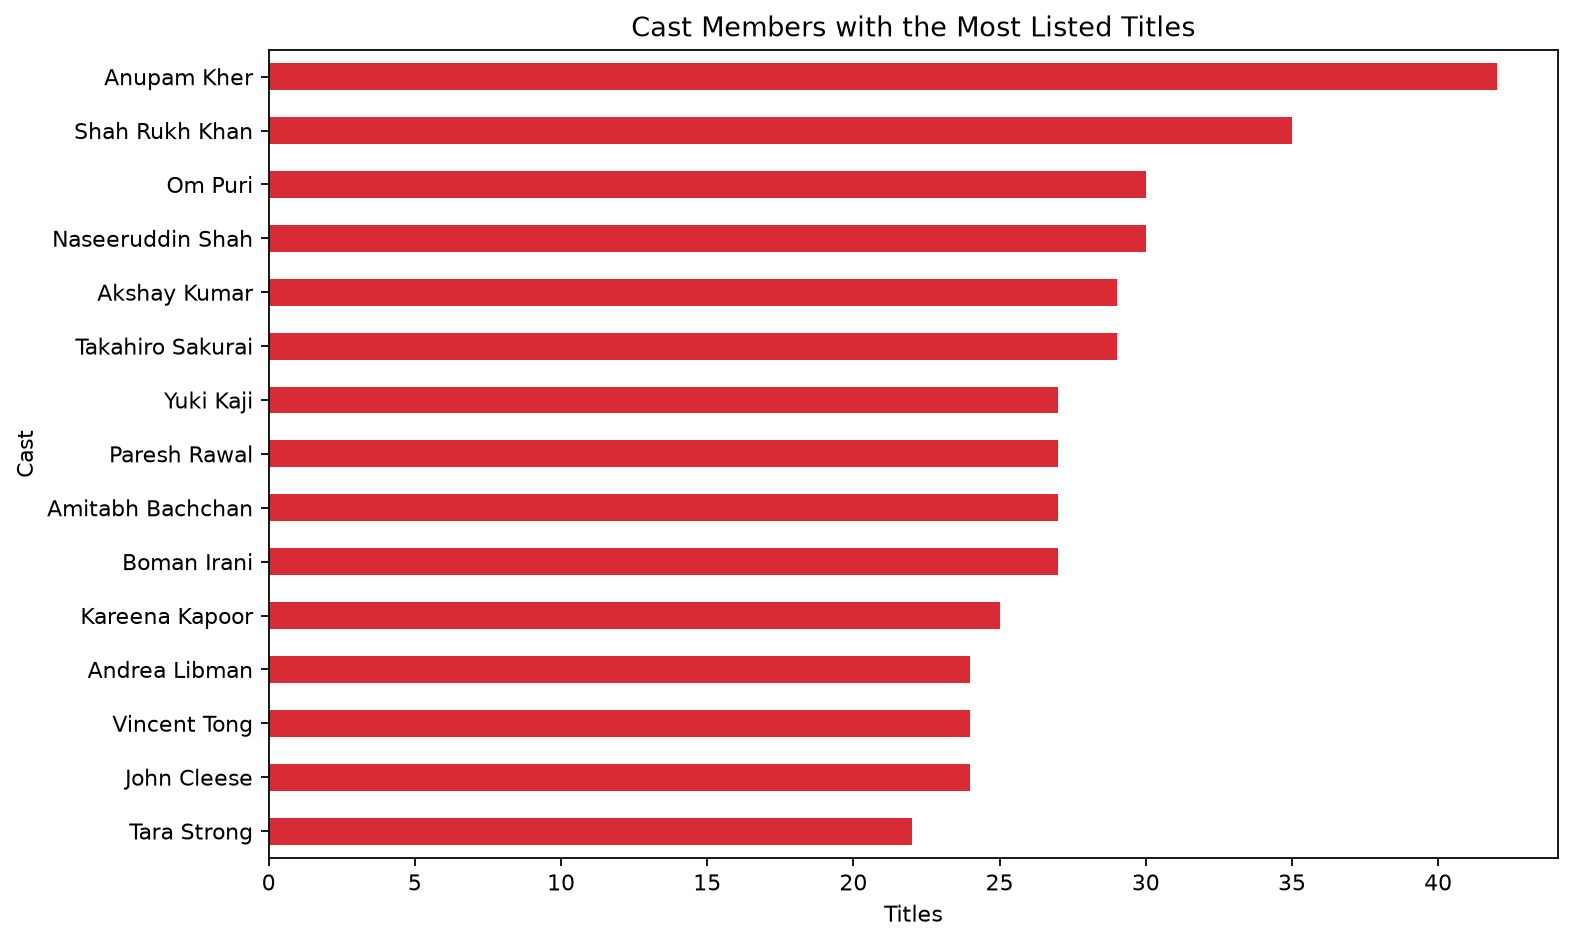

**INSIGHT:** Median Movie duration is 98 minutes; median TV Show duration is 1 seasons. These are separate measurements on separate plots and are not numerically comparable. Director/cast metadata are long-tailed and incomplete.

**BUSINESS RELEVANCE:** Format-aware duration summaries support catalog filters, while director and cast credits can enrich discovery when supplied.

In [12]:
display(Image(filename=str(FIGURES / "movie_duration_minutes.png")))
display(Image(filename=str(FIGURES / "tv_show_duration_seasons.png")))
display(Image(filename=str(FIGURES / "director_distribution.png")))
display(Image(filename=str(FIGURES / "cast_distribution.png")))
duration_summary = eda_results["duration_medians"]
display(Markdown(f"**INSIGHT:** Median Movie duration is {duration_summary['Movie_minutes']:.0f} minutes; median TV Show duration is {duration_summary['TV_Show_seasons']:.0f} seasons. These are separate measurements on separate plots and are not numerically comparable. Director/cast metadata are long-tailed and incomplete.\n\n**BUSINESS RELEVANCE:** Format-aware duration summaries support catalog filters, while director and cast credits can enrich discovery when supplied."))

## Stage 3 — Problem Statement & Business Objective

### 12. Problem statement

Netflix has a large catalog of Movies and TV Shows. **Can titles be grouped into meaningful clusters based on textual and content-related characteristics?**

This project selects **unsupervised clustering**. No ground-truth segment labels are available, and the objective is to explore similarities rather than predict ratings, classify genres, or build a recommendation engine.

### 13. Business objectives

1. Explore catalog segments and content discovery patterns.
2. Support catalog organization and genre/content segmentation.
3. Compare country and format patterns for regional analysis.
4. Provide descriptive evidence for content-strategy and acquisition discussions.
5. Produce possible audience-oriented groupings for later investigation.
6. Offer a clustering/segmentation preprocessing concept for future recommendation research; this project itself is **not** a recommendation system.

### 14. Business questions

- What content types, release periods, ratings, countries, and categories appear in this supplied catalog?
- Do observed content-type shares vary across date-added periods and listed countries?
- Can text similarities produce interpretable title groups?
- How stable and useful are K-Means and agglomerative groupings under internal metrics?


## Stage 4 — Model Building (Design)

The model implementation follows feature construction in Stage 6 so the notebook remains executable in the requested analytical order. We compare K-Means with Agglomerative Clustering, select K from measured evidence, and report internal metrics without claiming a ground-truth accuracy score.

## Stage 5 — Hypothesis Testing

The significance threshold is **α = 0.05**. Chi-square tests require independent observational units and expected cell counts large enough for the asymptotic approximation. The country test uses one first-listed country per title, top 10 countries plus `Other`, so each title appears once. Non-significant/significant results do not establish causation or business value by themselves.

### H1 — Type mix by date-added era

- **H₀:** Content type and broad date-added era are independent.
- **H₁:** Content-type distribution differs by era.
- A chi-square association test is paired with observed TV Show shares to examine direction. A significant association is not equivalent to a monotonic increase.
- The date-era chi-square test treats era as categorical; it tests association between content type and era, not an ordered/monotonic increase in TV Shows. The observed TV shares must be read directly and are not steadily increasing here.

### H2 — Type mix by primary listed country

- **H₀:** Content type is independent of primary listed country group.
- **H₁:** Content-type distribution differs across these country groups.
- This first-listed-country operationalization is incomplete for co-productions and is descriptive.

### H3 — Release-year distributions by type

- **H₀:** Movie and TV Show release-year distributions are equal.
- **H₁:** The distributions differ.
- The two-sided Mann–Whitney U test avoids a normality assumption for the skewed, discrete year values; titles are treated as independent rows.

For each association, the notebook reports effect size as well as p-value: Cramér's V for categorical chi-square tests, and rank-biserial correlation for the Mann–Whitney comparison. The three planned p-values are also shown with Holm family-wise adjustment; raw values remain visible. Statistical significance is distinct from practical importance, and no test establishes causation.


In [13]:
hypotheses = run_hypothesis_tests(clean_df, alpha=0.05)
for result in hypotheses:
    effect = (f"Cramer's V={result['cramers_v']:.4f}" if "cramers_v" in result else
              f"rank-biserial (Movie vs TV)={result['rank_biserial_movie_vs_tv']:.4f}")
    print(f"{result['hypothesis']}\nTest: {result['test']} | statistic={result['statistic']:.4g} | raw p={result['p_value']:.4g} | Holm p={result['p_value_holm']:.4g} | alpha={result['alpha']:.2f} | raw reject={result['reject_null']} | Holm reject={result['reject_null_holm']} | effect size={effect}")
    if result.get("assumption_min_expected") is not None:
        print(f"Minimum expected cell count: {result['assumption_min_expected']:.2f}")
    if result.get("direction_values"):
        print("Observed TV Show share by era:", {k: f"{v:.1%}" for k,v in result["direction_values"].items()})
    if result.get("median_movie_year") is not None:
        print("Release-year medians: Movie=", result["median_movie_year"], "TV Show=", result["median_tv_year"])
    print("Interpretation:", result["interpretation"], "\n")
with open(TABLES / "hypothesis_test_results.json", "w", encoding="utf-8") as f:
    json.dump(hypotheses, f, indent=2, ensure_ascii=False)
display(pd.DataFrame([{k: r.get(k) for k in ["hypothesis","test","statistic","degrees_of_freedom","p_value","p_value_holm","alpha","reject_null","reject_null_holm","cramers_v","rank_biserial_movie_vs_tv","assumption_min_expected"]} for r in hypotheses]))

H1: Catalog content type is associated with date-added era
Test: Pearson chi-square test of independence | statistic=6.311 | raw p=0.04262 | Holm p=0.04262 | alpha=0.05 | raw reject=True | Holm reject=True | effect size=Cramer's V=0.0285
Minimum expected cell count: 17.59
Observed TV Show share by era: {'2008-2014': '21.1%', '2015-2017': '32.8%', '2018-2021': '30.4%'}
Interpretation: Association indicates the type mix differs across eras; compare observed TV shares for direction. Date-added records describe the supplied catalog, not Netflix's full historical commissioning or availability. 

H2: Content type distribution differs by primary listed country
Test: Pearson chi-square test of independence | statistic=676.4 | raw p=7.385e-139 | Holm p=2.215e-138 | alpha=0.05 | raw reject=True | Holm reject=True | effect size=Cramer's V=0.2947
Minimum expected cell count: 33.42
Interpretation: A significant association is descriptive, not causal. Country metadata may be incomplete; the first-li

,hypothesis,test,statistic,degrees_of_freedom,p_value,p_value_holm,alpha,reject_null,reject_null_holm,cramers_v,rank_biserial_movie_vs_tv,assumption_min_expected
0,H1: Catalog content type is associated with da...,Pearson chi-square test of independence,6.310642e+00,2.0,4.262472e-02,4.262472e-02,0.05,True,True,0.028486,NaN,17.590330
1,H2: Content type distribution differs by prima...,Pearson chi-square test of independence,6.763763e+02,10.0,7.384729e-139,2.215419e-138,0.05,True,True,0.294720,NaN,33.424939
2,H3: Release-year distributions differ between ...,Two-sided Mann-Whitney U test,4.666842e+06,NaN,7.507434e-88,1.501487e-87,0.05,True,True,NaN,-0.279729,NaN


In [14]:
display(Markdown(
    f"**Practical magnitude:** date-era Cramér's V={hypotheses[0]['cramers_v']:.4f}; primary-country Cramér's V={hypotheses[1]['cramers_v']:.4f}; release-year rank-biserial effect={hypotheses[2]['rank_biserial_movie_vs_tv']:.4f} (negative means Movie years tend lower than TV Show years under this ordering). The date-era result is an association test only, and its observed TV shares are not monotonic. P-values address compatibility with the null under test assumptions; effect sizes describe magnitude, and neither establishes business impact."))

**Practical magnitude:** date-era Cramér's V=0.0285; primary-country Cramér's V=0.2947; release-year rank-biserial effect=-0.2797 (negative means Movie years tend lower than TV Show years under this ordering). The date-era result is an association test only, and its observed TV shares are not monotonic. P-values address compatibility with the null under test assumptions; effect sizes describe magnitude, and neither establishes business impact.

## Stage 6 — Feature Engineering & Pre-processing

### 15. Metadata feature engineering

In [15]:
featured_df = add_metadata_features(make_text_features(clean_df))
metadata_features = [c for c in ["year_added","country_count","category_count","cast_member_count","director_count","duration_value","duration_unit"] if c in featured_df]
display(featured_df[["show_id","title","type","release_year"] + metadata_features].head())
print("Text fields used when present:", [c for c in ["title","director","cast","country","listed_in","description"] if c in featured_df.columns])

,show_id,title,type,release_year,year_added,country_count,category_count,cast_member_count,director_count,duration_value,duration_unit
0,s1,3%,TV Show,2020,2020,1,3,11,0,4,Season
1,s2,7:19,Movie,2016,2016,1,2,6,1,93,min
2,s3,23:59,Movie,2011,2018,1,2,9,1,78,min
3,s4,9,Movie,2009,2017,1,3,9,1,80,min
4,s5,21,Movie,2008,2020,1,1,12,1,123,min


Text fields used when present: ['title', 'director', 'cast', 'country', 'listed_in', 'description']


### 16. Combined text and preprocessing

`combined_text` joins available `title`, `director`, `cast`, `country`, `listed_in`, and `description`. The fields provide names, credits, geography, categories, and synopsis language that can express content similarity. Missing values become empty only in this derived NLP representation. The normalized copy is lowercased, punctuation is replaced with spaces while Unicode letters/digits are preserved, and whitespace is collapsed. English stop words are handled by the vectorizers. Source metadata remains unchanged.

Numeric metadata (release year, counts, duration) is retained for interpretation/EDA and not appended to the text distance space. This avoids mixing arbitrary numeric scale with sparse text similarity. `StandardScaler` is therefore not applied to the primary representation.


In [16]:
display(featured_df[["title","combined_text","normalized_text"]].head(3))
print("Rows with empty normalized text:", int(featured_df.normalized_text.eq("").sum()))

,title,combined_text,normalized_text
0,3%,"3% João Miguel, Bianca Comparato, Michel Gome...",3 joão miguel bianca comparato michel gomes ro...
1,7:19,"7:19 Jorge Michel Grau Demián Bichir, Héctor B...",7 19 jorge michel grau demián bichir héctor bo...
2,23:59,"23:59 Gilbert Chan Tedd Chan, Stella Chung, He...",23 59 gilbert chan tedd chan stella chung henl...


Rows with empty normalized text: 0


### 17. TF-IDF and Bag of Words

**Term Frequency (TF)** counts a term within a title document. **Inverse Document Frequency (IDF)** downweights terms common across many documents. **TF-IDF** combines both so a term receives higher weight when it is informative for a title and less weight when ubiquitous. A sparse matrix makes cosine similarity practical without densifying the vocabulary matrix.

CountVectorizer is also run as a Bag-of-Words baseline: it records token counts, without the same common-term downweighting. TF-IDF is the primary representation.


In [17]:
tfidf, tfidf_vectorizer, bow, bow_vectorizer = vectorize_text(featured_df["normalized_text"])
representation_summary = pd.DataFrame([
    {"representation":"TF-IDF (1-2 grams)","rows":tfidf.shape[0],"features":tfidf.shape[1],"nonzeros":tfidf.nnz,"density":tfidf.nnz/(tfidf.shape[0]*tfidf.shape[1])},
    {"representation":"Bag of Words (unigrams)","rows":bow.shape[0],"features":bow.shape[1],"nonzeros":bow.nnz,"density":bow.nnz/(bow.shape[0]*bow.shape[1])},
])
display(representation_summary)
print("Sparse TF-IDF matrix:", tfidf.shape, "| density:", f"{tfidf.nnz/(tfidf.shape[0]*tfidf.shape[1]):.4%}")

,representation,rows,features,nonzeros,density
0,TF-IDF (1-2 grams),7787,30000,332557,0.001424
1,Bag of Words (unigrams),7787,23570,257815,0.001405


Sparse TF-IDF matrix: (7787, 30000) | density: 0.1424%


### 18. Numerical and dimensionality preprocessing

TruncatedSVD reduces the sparse TF-IDF matrix to a dense 100-component representation for clustering and visualization. Rows are L2-normalized after projection so Euclidean clustering is not dominated by vector magnitude. The 100-component space captures only part of original TF-IDF variability; the 2D map is a qualitative projection, not proof of clean separation. The original sparse TF-IDF matrix stays sparse.


### 19. K-Means: selecting K, elbow, and silhouette

#### Stage 4 continued — Model implementation

Candidate K values are fitted over 2–10. Inertia must decrease as K grows, so it is interpreted with the elbow shape and a sampled cosine silhouette score (higher is better). The selection rule used here chooses the smallest K within 1% of the best sampled silhouette. This is a transparent complexity trade-off; it does not claim one objectively true number of segments.


,k,inertia,silhouette_sample
0,2,6658.390655,0.094226
1,3,6354.412347,0.122798
2,4,6166.866660,0.141985
3,5,6031.177864,0.144485
4,6,5866.148171,0.146607
5,7,5739.836256,0.166151
6,8,5610.661299,0.162089
7,9,5488.106008,0.178269
8,10,5385.365910,0.178047


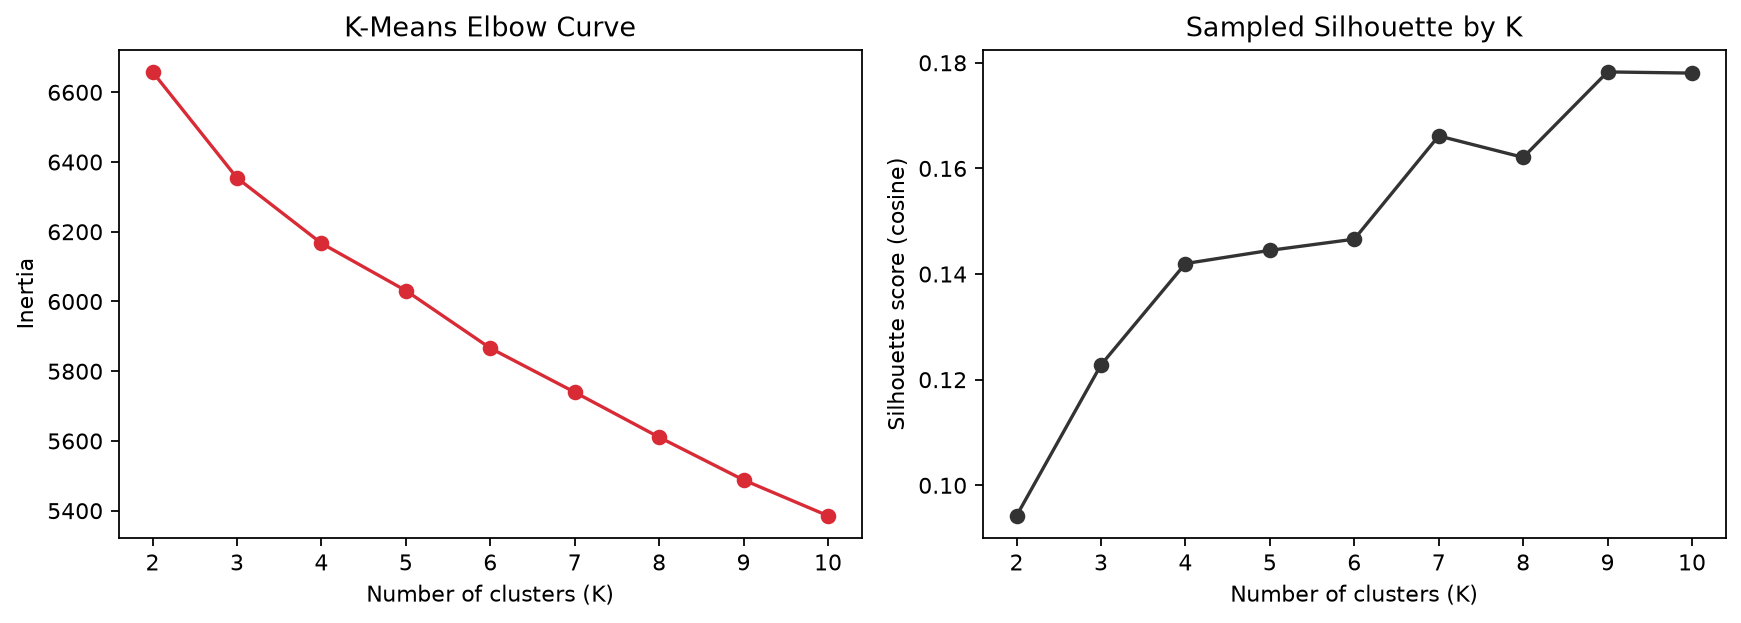

Selected K by stated rule: 9


**INSIGHT:** The selected value is K=9, based on the observed inertia curve and candidate sampled silhouette scores.

**BUSINESS RELEVANCE:** A documented selection rule makes segment counts reviewable; stakeholders should treat segments as exploratory organization aids.

In [18]:
model_results = run_models(clean_df, PROJECT_ROOT, k_values=range(2,11),
                           agglomerative_sample_size=1500, random_state=42)
k_selection = model_results["k_selection"]
selected_k = model_results["selected_k"]
display(k_selection)
display(Image(filename=str(FIGURES / "elbow_and_silhouette.png")))
print("Selected K by stated rule:", selected_k)
display(Markdown(f"**INSIGHT:** The selected value is K={selected_k}, based on the observed inertia curve and candidate sampled silhouette scores.\n\n**BUSINESS RELEVANCE:** A documented selection rule makes segment counts reviewable; stakeholders should treat segments as exploratory organization aids."))

### 20. Final K-Means model

,titles,percentage
0,760,9.76
1,761,9.77
2,1525,19.58
3,494,6.34
4,378,4.85
5,1394,17.90
6,406,5.21
7,1464,18.80
8,605,7.77


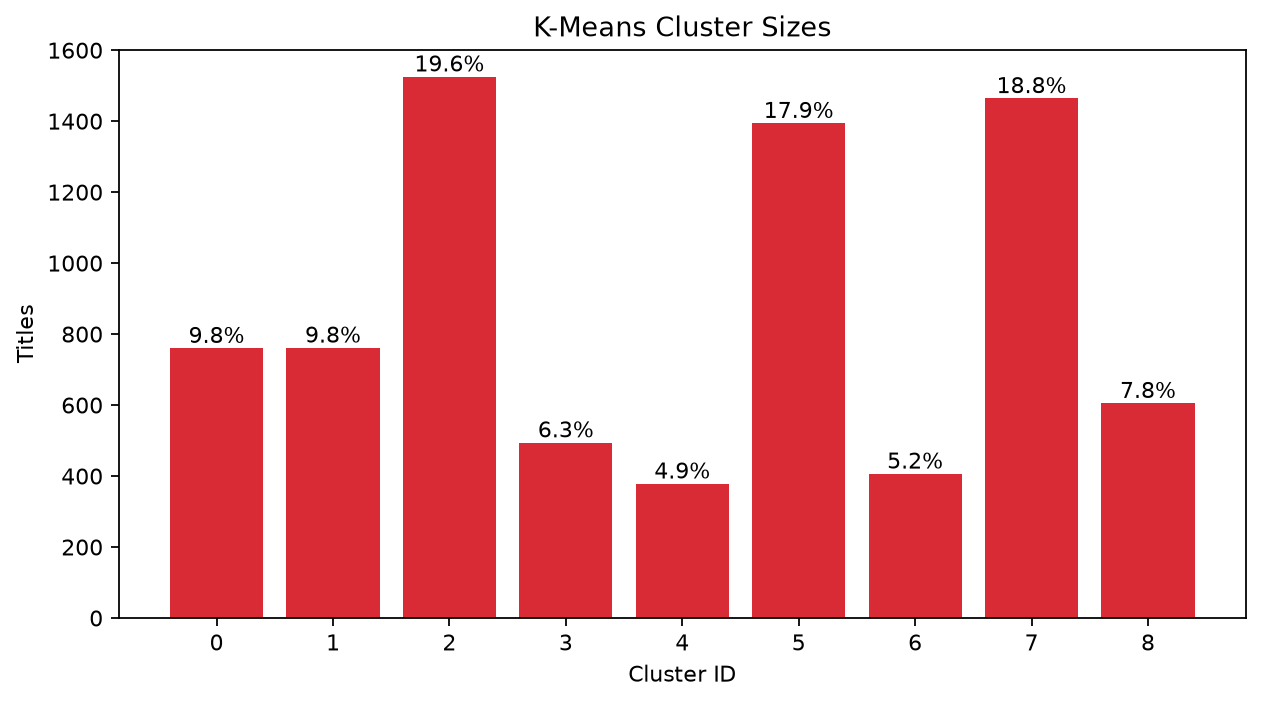

Assignments saved to: outputs/tables/kmeans_cluster_assignments.csv


In [19]:
labels = model_results["kmeans_labels"]
cluster_sizes = pd.Series(labels).value_counts().sort_index().rename("titles").to_frame()
cluster_sizes["percentage"] = (cluster_sizes["titles"] / len(labels) * 100).round(2)
display(cluster_sizes)
display(Image(filename=str(FIGURES / "cluster_sizes.png")))
print("Assignments saved to:", "outputs/tables/kmeans_cluster_assignments.csv")

### 21. Agglomerative hierarchical clustering and dendrogram

A complete hierarchical fit on all titles requires quadratic pairwise storage/work and is unnecessary for this exploratory comparison. We use a reproducible 1,500-title sample, evaluate Ward/Euclidean and average/cosine linkage over cluster counts near the selected K, then draw a readable truncated dendrogram from a further 300-title representative subset. Hierarchical assignments are therefore sample assignments, not a full-catalog deployment model.


,linkage,metric,n_clusters,silhouette_cosine
3,ward,euclidean,10,0.135872
2,ward,euclidean,9,0.125636
0,ward,euclidean,7,0.115939
1,ward,euclidean,8,0.115785
6,average,cosine,9,0.074025
5,average,cosine,8,0.072651
7,average,cosine,10,0.067886
4,average,cosine,7,0.060303


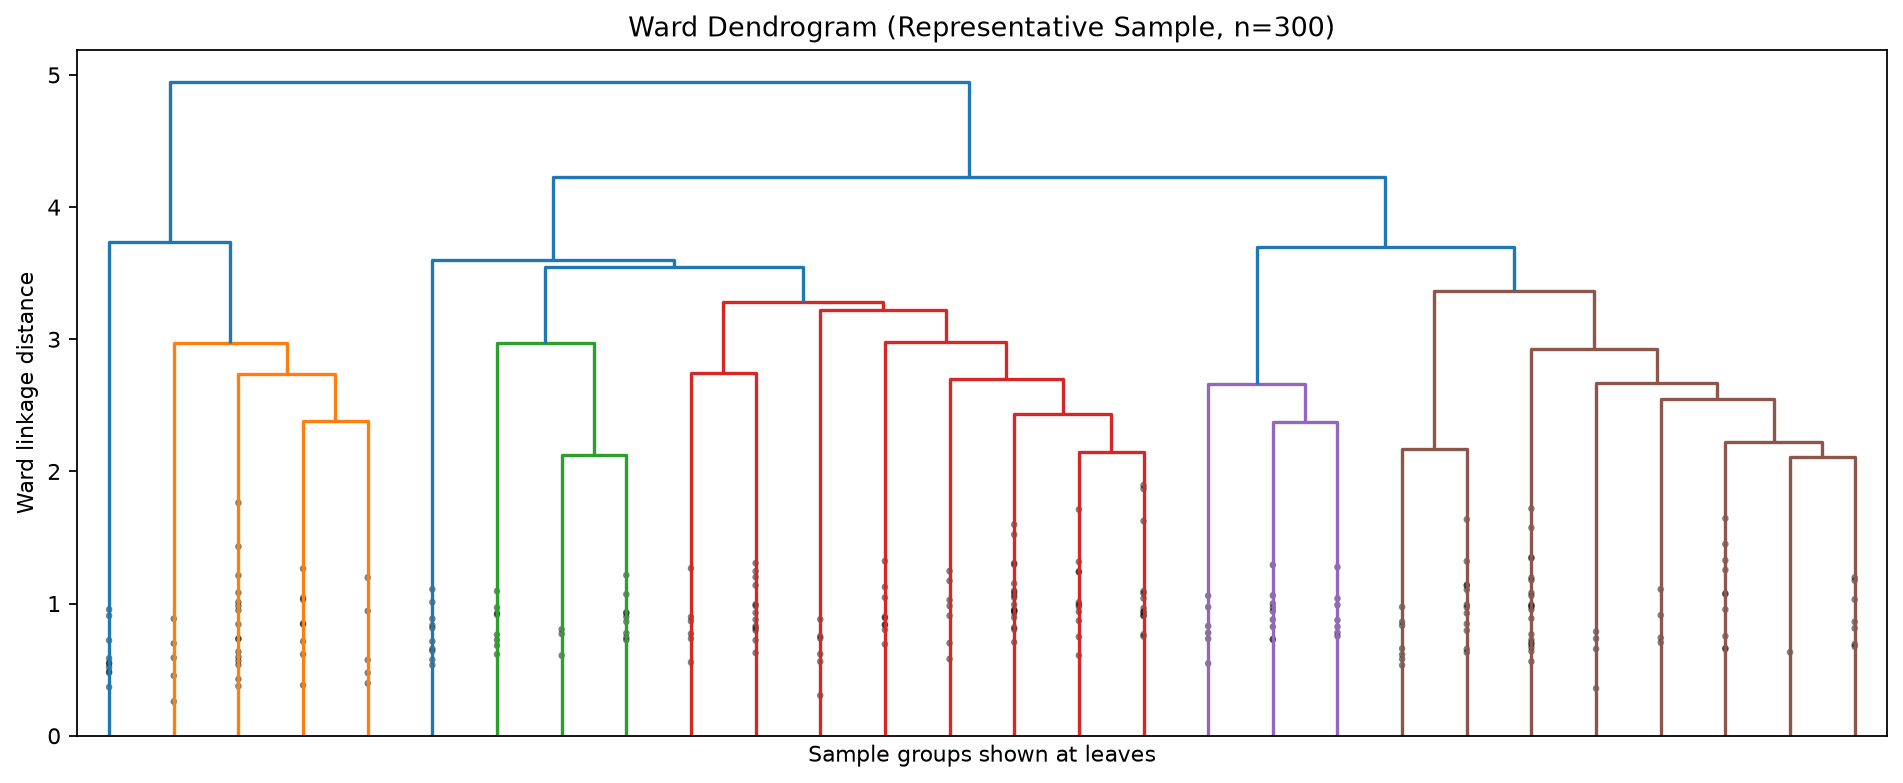

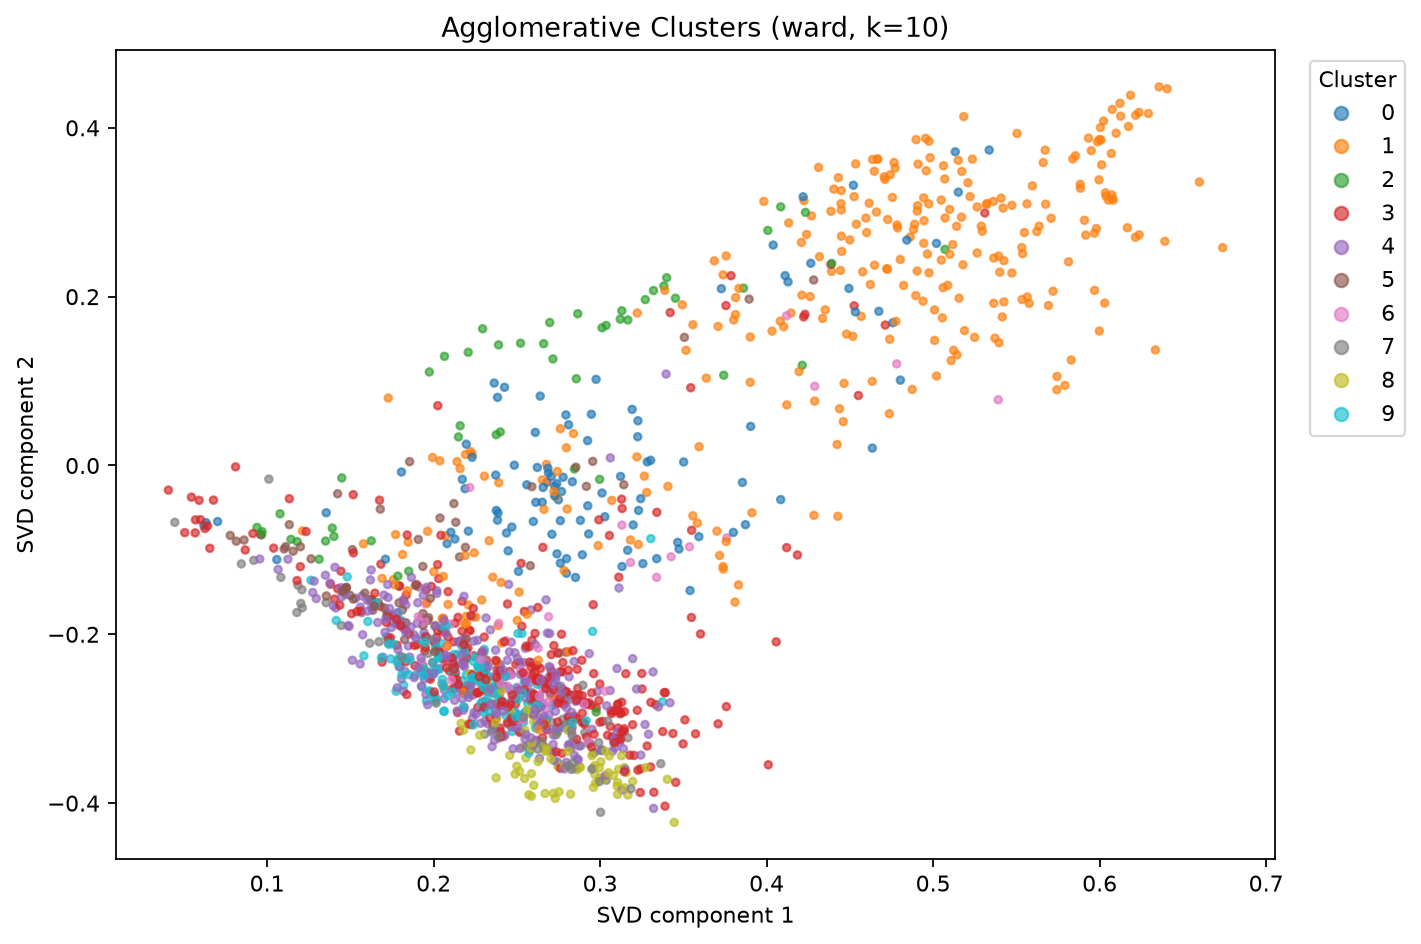

Selected linkage and cluster count: ward 10
Agglomerative sample size: 1500


In [20]:
display(model_results["agglomerative_selection"])
display(Image(filename=str(FIGURES / "dendrogram.png")))
display(Image(filename=str(FIGURES / "agglomerative_cluster_visualization.png")))
print("Selected linkage and cluster count:", model_results["selected_linkage"], model_results["hierarchy_k"])
print("Agglomerative sample size:", len(model_results["agglomerative_labels"]))

### 22. Model evaluation and comparison

Metrics are computed for both methods on the same 1,500-title sample in the normalized SVD space:

- **Cosine silhouette**: cohesion/separation from cosine geometry; higher is better, range −1 to 1.
- **Davies–Bouldin**: average similarity to the most similar competing cluster under Euclidean geometry; lower is better.
- **Calinski–Harabasz**: between-cluster dispersion relative to within-cluster dispersion under Euclidean geometry; higher is better.
- **Inertia**: K-Means within-cluster squared Euclidean error over the full fitted catalog; lower as K rises, so compare only alongside K.

Internal metrics do not establish semantic truth. Mixed text fields, high sparsity, and the SVD projection affect these values.


#### Original selected-configuration results (model selection)

This table retains each algorithm's selected configuration. K-Means K is selected by its stated 1% silhouette rule; Agglomerative linkage/K is chosen from its own sampled linkage/K search. Since their K values can differ, this table is not a controlled same-K algorithm comparison.

In [21]:
selected_comparison = model_results["metrics"]
display(selected_comparison)

,algorithm,n_clusters_requested,n_evaluated,n_clusters_observed,silhouette_cosine,davies_bouldin_euclidean,calinski_harabasz_euclidean,inertia
0,K-Means,9,1500,9,0.176875,2.953323,52.697037,5488.106008
1,Agglomerative (ward),10,1500,10,0.135872,3.116421,42.086808,NaN


#### Matched-K algorithm comparison

For a controlled comparison, both methods use K equal to the selected K-Means K, with labels evaluated on every row of the same reproducible 1,500-title sample. This comparison is reported separately from model selection. Silhouette uses cosine geometry; Davies–Bouldin and Calinski–Harabasz use Euclidean geometry in the same normalized SVD space.

In [22]:
comparison = model_results["same_k_metrics"]
display(comparison)
km_row, ag_row = comparison.iloc[0], comparison.iloc[1]
display(Markdown(
    f"**Matched-K interpretation (K={int(km_row.n_clusters_requested)}):** On the same {int(km_row.n_evaluated):,}-title evaluation sample, K-Means has cosine silhouette {km_row.silhouette_cosine:.3f} vs {ag_row.silhouette_cosine:.3f} for Agglomerative Ward, Davies–Bouldin {km_row.davies_bouldin_euclidean:.3f} vs {ag_row.davies_bouldin_euclidean:.3f} (lower is better), and Calinski–Harabasz {km_row.calinski_harabasz_euclidean:.2f} vs {ag_row.calinski_harabasz_euclidean:.2f} (higher is better). These internal metrics describe this representation and sample only; they do not establish semantic or business superiority. K-Means is used for full-catalog interpretation, while hierarchy provides a sample-based second view."
))

,algorithm,n_clusters_requested,n_evaluated,n_clusters_observed,silhouette_cosine,davies_bouldin_euclidean,calinski_harabasz_euclidean
0,K-Means (K=9),9,1500,9,0.176875,2.953323,52.697037
1,Agglomerative Ward (K=9),9,1500,9,0.125636,3.038032,42.971280


**Matched-K interpretation (K=9):** On the same 1,500-title evaluation sample, K-Means has cosine silhouette 0.177 vs 0.126 for Agglomerative Ward, Davies–Bouldin 2.953 vs 3.038 (lower is better), and Calinski–Harabasz 52.70 vs 42.97 (higher is better). These internal metrics describe this representation and sample only; they do not establish semantic or business superiority. K-Means is used for full-catalog interpretation, while hierarchy provides a sample-based second view.

### 23. Cluster visualization

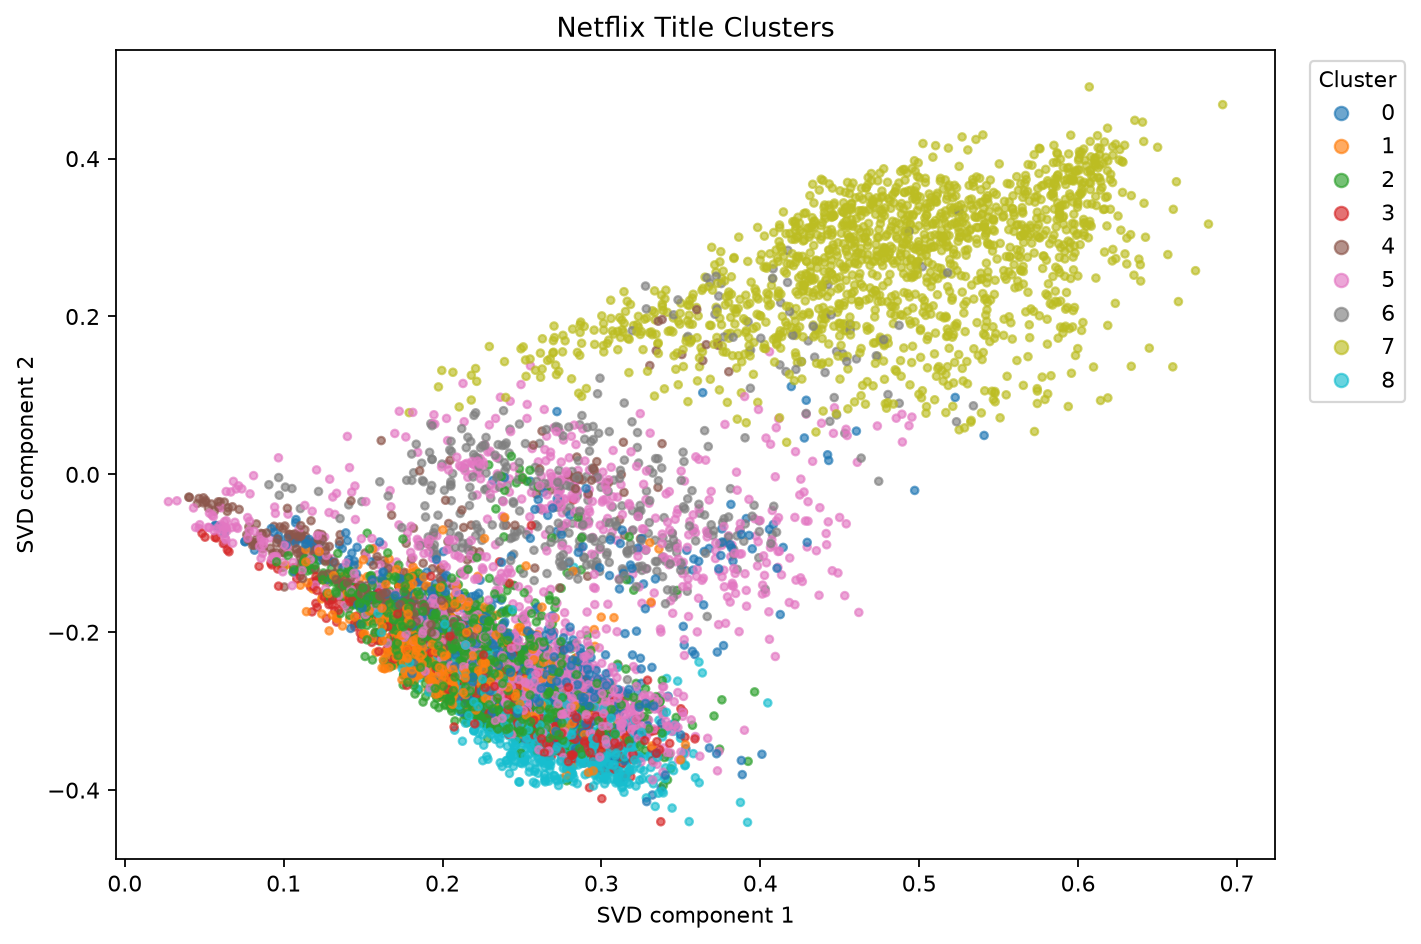

**INSIGHT:** Each point is a title projected to the first two SVD components, colored by K-Means label. Overlap is expected because only two dimensions are shown.

**BUSINESS RELEVANCE:** This is a visual overview for discussion; it should not be used to claim that titles are perfectly separated.

In [23]:
display(Image(filename=str(FIGURES / "cluster_visualization.png")))
display(Markdown("**INSIGHT:** Each point is a title projected to the first two SVD components, colored by K-Means label. Overlap is expected because only two dimensions are shown.\n\n**BUSINESS RELEVANCE:** This is a visual overview for discussion; it should not be used to claim that titles are perfectly separated."))

### 24. Cluster interpretation and cluster strategy


Cluster 0 — Movie-focused · Action & Adventure-led
Size: 760 (9.76%)
Content type share (%): {'Movie': 92.9, 'TV Show': 7.1}
Common countries: ['United States', 'India', 'United Kingdom', 'Hong Kong', 'China']
Common ratings: ['TV-14', 'TV-MA', 'R', 'PG-13', 'TV-PG']
Common genres: ['Action & Adventure', 'International Movies', 'Dramas', 'Comedies', 'Sci-Fi & Fantasy']
K-Means centroid terms (approximate TF-IDF projection): ['action', 'adventure', 'action adventure', 'states action', 'adventure dramas', 'international movies', 'movies', 'united', 'united states', 'adventure comedies', 'states', 'india action']
Cluster mean TF-IDF terms: ['action', 'action adventure', 'adventure', 'states action', 'adventure dramas', 'international movies', 'movies', 'adventure comedies', 'united', 'india action', 'international', 'united states']
Representative titles: ['Waarrior Savitri', 'Iceman', 'Di Renjie zhi Sidatianwang', 'The Bund', 'Stargate SG-1']


,title,description
1741,Di Renjie zhi Sidatianwang,Framed by an empress who plans to steal a drag...
2935,Iceman,Four hundred years after they were frozen in t...
5795,Stargate SG-1,Stargate Command roars into action when Jack O...
6186,The Bund,"After losing everything, a young man rebuilds ..."
7454,Waarrior Savitri,"In a modern adaptation of a mythological tale,..."


Characteristics: Movie-focused; strongest listed category is Action & Adventure; terms and example synopses above provide the text evidence.
Business interpretation: Potential use: use this action & adventure-led movie segment for navigation and acquisition discussions; validate title fit and audience utility before operational use.


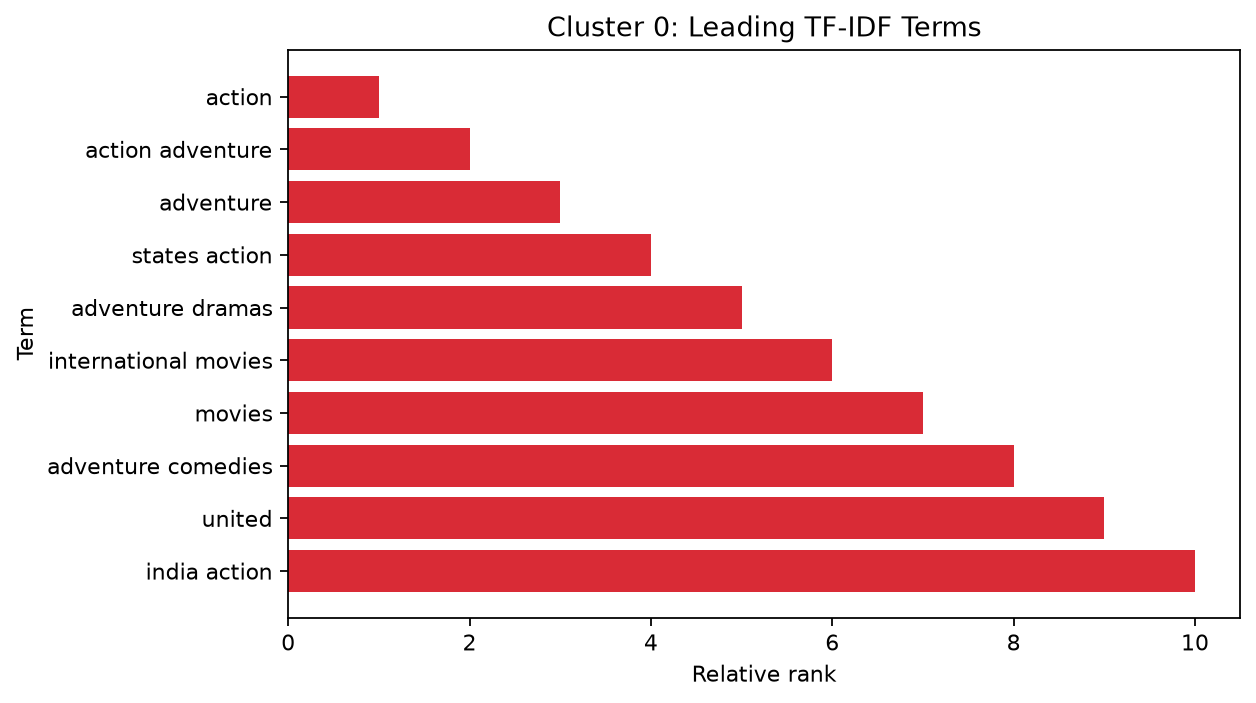


Cluster 1 — Movie-focused · Documentaries-led
Size: 761 (9.77%)
Content type share (%): {'Movie': 100.0}
Common countries: ['United States', 'United Kingdom', 'Canada', 'France', 'India']
Common ratings: ['TV-MA', 'TV-14', 'TV-PG', 'TV-G', 'PG-13']
Common genres: ['Documentaries', 'International Movies', 'Music & Musicals', 'Sports Movies', 'LGBTQ Movies']
K-Means centroid terms (approximate TF-IDF projection): ['documentaries', 'states documentaries', 'documentary', 'united', 'documentaries international', 'states', 'united states', 'movies', 'international movies', 'international', 'kingdom documentaries', 'music']
Cluster mean TF-IDF terms: ['documentaries', 'states documentaries', 'documentary', 'documentaries international', 'united', 'states', 'united states', 'movies', 'international movies', 'kingdom documentaries', 'music', 'international']
Representative titles: ['Trophy', 'Iverson', 'The Gentleman Driver', "ZZ TOP: THAT LITTLE OL' BAND FROM TEXAS", 'Senna']


,title,description
3085,Iverson,This unfiltered documentary follows the rocky ...
5492,Senna,This fast-paced documentary profiles Ayrton Se...
6387,The Gentleman Driver,This documentary follows four tycoons who moon...
7235,Trophy,This documentary explores the tensions between...
7786,ZZ TOP: THAT LITTLE OL' BAND FROM TEXAS,This documentary delves into the mystique behi...


Characteristics: Movie-focused; strongest listed category is Documentaries; terms and example synopses above provide the text evidence.
Business interpretation: Potential use: use this documentaries-led movie segment for navigation and acquisition discussions; validate title fit and audience utility before operational use.


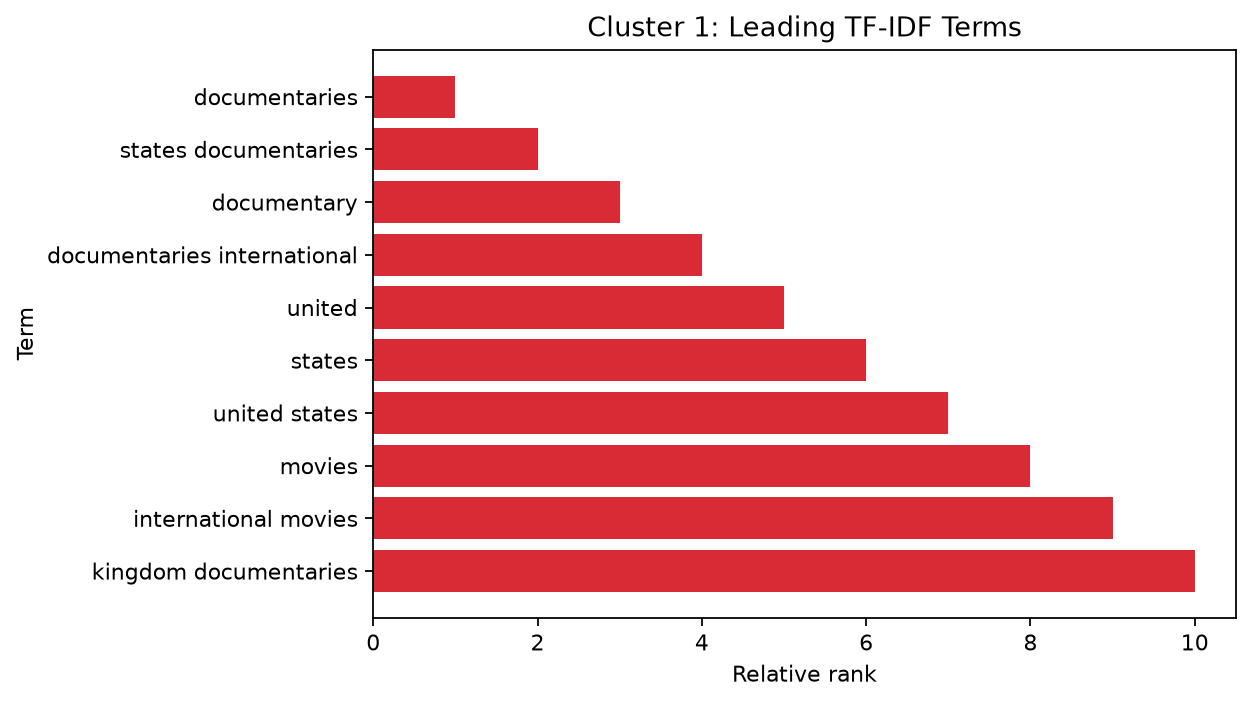


Cluster 2 — Movie-focused · International Movies-led
Size: 1525 (19.58%)
Content type share (%): {'Movie': 100.0}
Common countries: ['India', 'Spain', 'France', 'Egypt', 'Turkey']
Common ratings: ['TV-14', 'TV-MA', 'TV-PG', 'R', 'PG-13']
Common genres: ['International Movies', 'Dramas', 'Comedies', 'Romantic Movies', 'Thrillers']
K-Means centroid terms (approximate TF-IDF projection): ['international movies', 'movies', 'dramas international', 'international', 'dramas', 'india', 'comedies', 'comedies international', 'movies romantic', 'romantic movies', 'india dramas', 'romantic']
Cluster mean TF-IDF terms: ['international movies', 'movies', 'dramas international', 'international', 'dramas', 'india', 'comedies', 'comedies international', 'movies romantic', 'romantic movies', 'india dramas', 'romantic']
Representative titles: ['Kacche Dhaagey', "Okafor's Law", 'Kuppivala', 'Rehmataan', 'The Light of My Eyes']


,title,description
3284,Kacche Dhaagey,"While visiting India for her cousin's wedding,..."
3470,Kuppivala,A young woman talented at traditional dance fi...
4597,Okafor's Law,An unapologetic lothario sets out to seduce th...
5145,Rehmataan,"As unemployment, drug addiction and corruption..."
6596,The Light of My Eyes,A composer hides his love for his formerly bli...


Characteristics: Movie-focused; strongest listed category is International Movies; terms and example synopses above provide the text evidence.
Business interpretation: Potential use: use this international movies-led movie segment for navigation and acquisition discussions; validate title fit and audience utility before operational use.


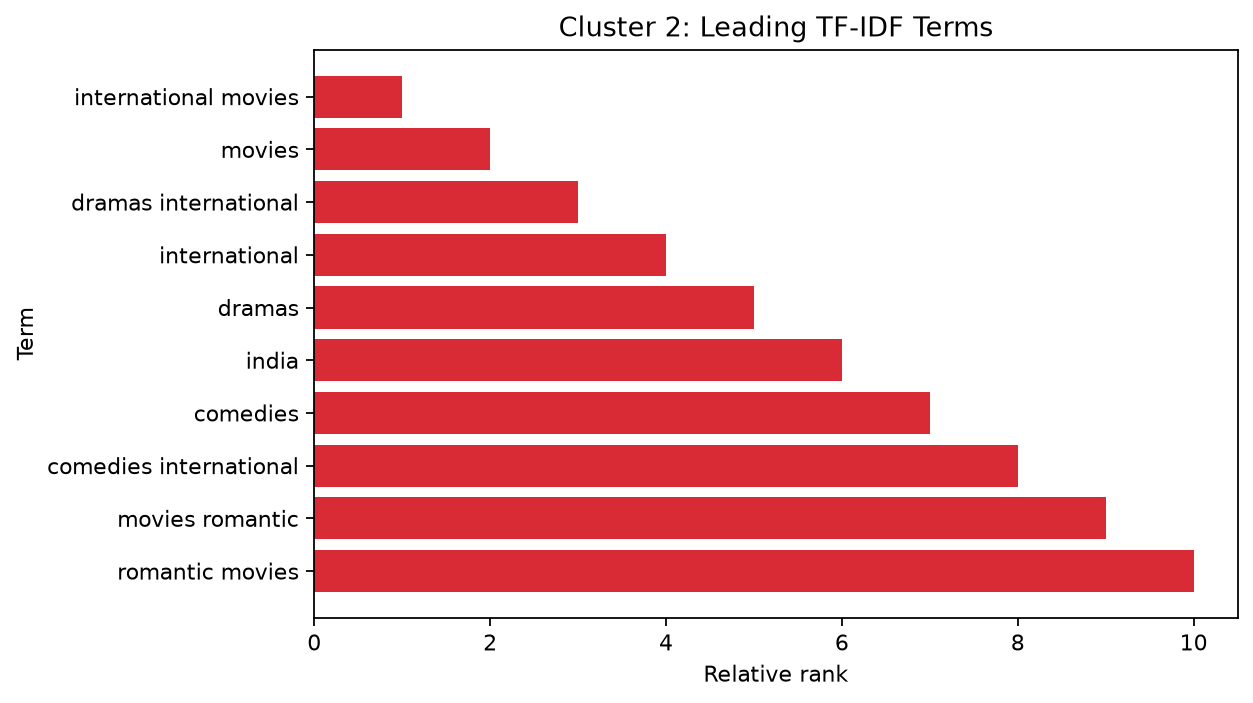


Cluster 3 — Movie-focused · Children & Family Movies-led
Size: 494 (6.34%)
Content type share (%): {'Movie': 100.0}
Common countries: ['United States', 'Canada', 'United Kingdom', 'France', 'Australia']
Common ratings: ['PG', 'TV-Y', 'TV-Y7', 'TV-PG', 'TV-G']
Common genres: ['Children & Family Movies', 'Comedies', 'Dramas', 'Music & Musicals', 'Romantic Movies']
K-Means centroid terms (approximate TF-IDF projection): ['children', 'family', 'children family', 'family movies', 'states children', 'movies comedies', 'movies', 'united', 'united states', 'states', 'comedies', 'christmas']
Cluster mean TF-IDF terms: ['children family', 'family movies', 'children', 'family', 'states children', 'movies comedies', 'movies', 'united', 'united states', 'states', 'comedies', 'christmas']
Representative titles: ['Holly Star', 'Tellur Aliens', 'Beary Tales', 'Santa Claws', 'Chitty Chitty Bang Bang']


,title,description
782,Beary Tales,A well-known wildlife photographer living alon...
1344,Chitty Chitty Bang Bang,Quirky inventor Caractacus Potts and his famil...
2776,Holly Star,"Home for the holidays, a broke puppeteer knows..."
5381,Santa Claws,When a gift sack full of kittens gives Santa a...
6018,Tellur Aliens,Three teenaged best friends on the planet Tell...


Characteristics: Movie-focused; strongest listed category is Children & Family Movies; terms and example synopses above provide the text evidence.
Business interpretation: Potential use: use this children & family movies-led movie segment for navigation and acquisition discussions; validate title fit and audience utility before operational use.


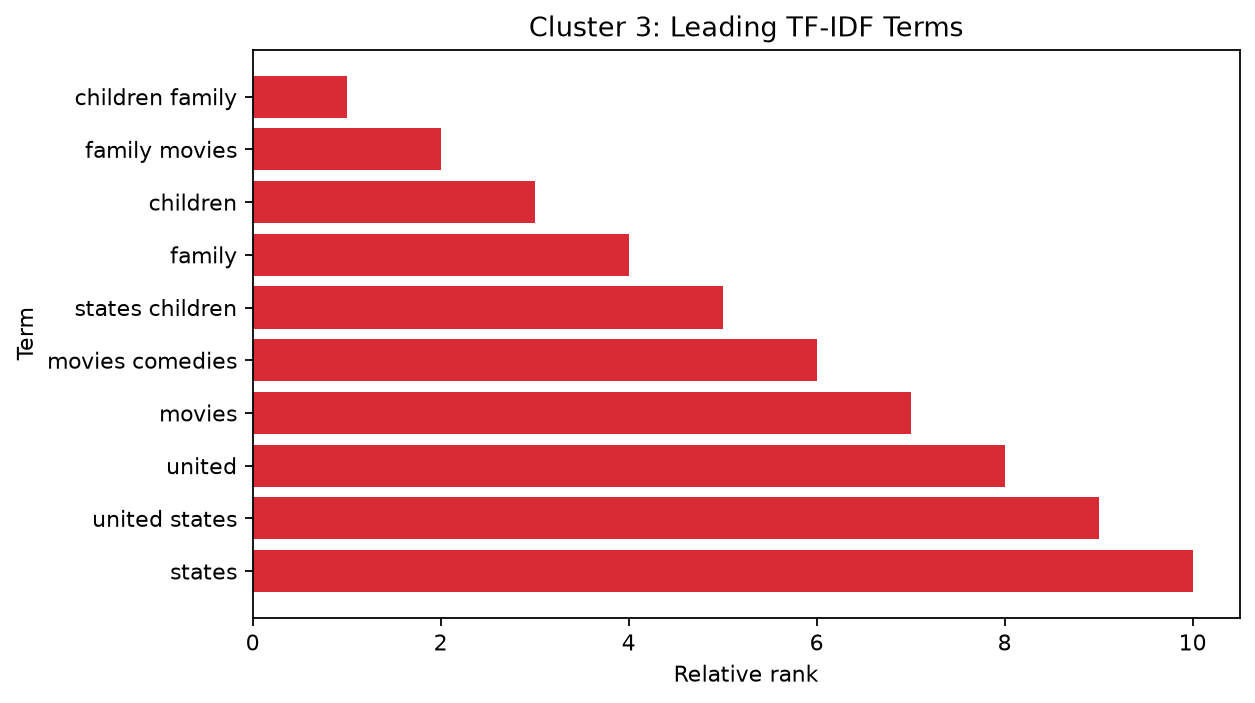


Cluster 4 — Movie-focused · Stand-Up Comedy-led
Size: 378 (4.85%)
Content type share (%): {'Movie': 87.6, 'TV Show': 12.4}
Common countries: ['United States', 'United Kingdom', 'Mexico', 'India', 'Brazil']
Common ratings: ['TV-MA', 'TV-14', 'TV-PG', 'R', 'NR']
Common genres: ['Stand-Up Comedy', 'Stand-Up Comedy & Talk Shows', 'TV Comedies', 'International TV Shows', 'Music & Musicals']
K-Means centroid terms (approximate TF-IDF projection): ['stand', 'comedy', 'stand comedy', 'states stand', 'special', 'comedian', 'united', 'united states', 'states', 'comic', 'stand special', 'talk']
Cluster mean TF-IDF terms: ['stand', 'comedy', 'stand comedy', 'states stand', 'comedian', 'special', 'united', 'united states', 'states', 'comic', 'talk', 'stand special']
Representative titles: ['Chelsea', 'Daniel Sloss: Live Shows', 'Queens of Comedy', 'The Comedy Lineup', 'Hari Kondabolu: Warn Your Relatives']


,title,description
1307,Chelsea,"It's not her first talk show, but it is a firs..."
1600,Daniel Sloss: Live Shows,Comedian Daniel Sloss is ready to find the fun...
2626,Hari Kondabolu: Warn Your Relatives,"Hari Kondabolu breaks down identity politics, ..."
5035,Queens of Comedy,Eight women perform in front of celebrity judg...
6232,The Comedy Lineup,A diverse group of up-and-coming comedians per...


Characteristics: Movie-focused; strongest listed category is Stand-Up Comedy; terms and example synopses above provide the text evidence.
Business interpretation: Potential use: use this stand-up comedy-led movie segment for navigation and acquisition discussions; validate title fit and audience utility before operational use.


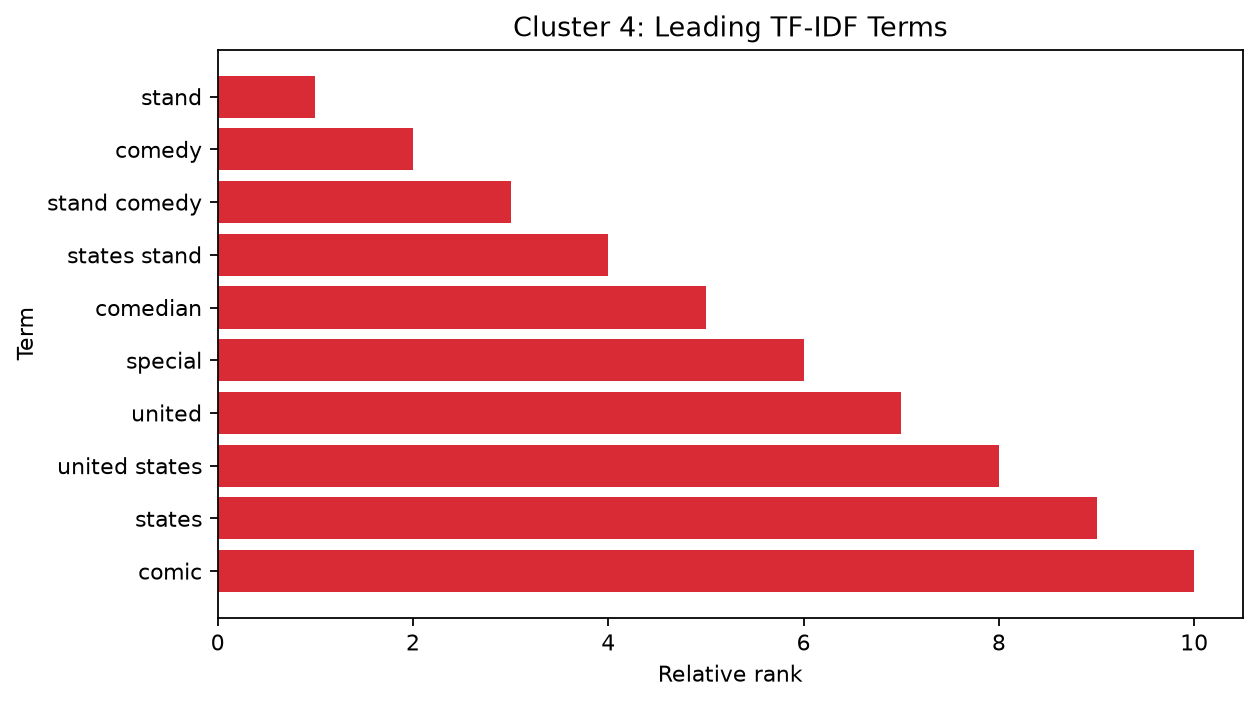


Cluster 5 — Movie-focused · Dramas-led
Size: 1394 (17.90%)
Content type share (%): {'Movie': 68.4, 'TV Show': 31.6}
Common countries: ['United States', 'United Kingdom', 'Canada', 'Australia', 'Germany']
Common ratings: ['TV-MA', 'R', 'TV-14', 'PG-13', 'TV-PG']
Common genres: ['Dramas', 'Comedies', 'Thrillers', 'Horror Movies', 'Romantic Movies']
K-Means centroid terms (approximate TF-IDF projection): ['united', 'states', 'united states', 'comedies', 'tv', 'dramas', 'states dramas', 'movies', 'thrillers', 'michael', 'states comedies', 'john']
Cluster mean TF-IDF terms: ['united', 'united states', 'states', 'tv', 'dramas', 'states dramas', 'comedies', 'movies', 'states comedies', 'thrillers', 'docuseries', 'michael']
Representative titles: ['Babies', 'Absurd Planet', 'High Risk', 'Girls Incarcerated', 'High Score']


,title,description
289,Absurd Planet,A cast of quirky critters and Mother Nature he...
667,Babies,"From nature to nurture, this docuseries explor..."
2430,Girls Incarcerated,"Fights, friendships, dating, rules. Teenage li..."
2730,High Risk,"From scientists to snake handlers, this series..."
2731,High Score,This docuseries traces the history of classic ...


Characteristics: Movie-focused; strongest listed category is Dramas; terms and example synopses above provide the text evidence.
Business interpretation: Potential use: use this dramas-led movie segment for navigation and acquisition discussions; validate title fit and audience utility before operational use.


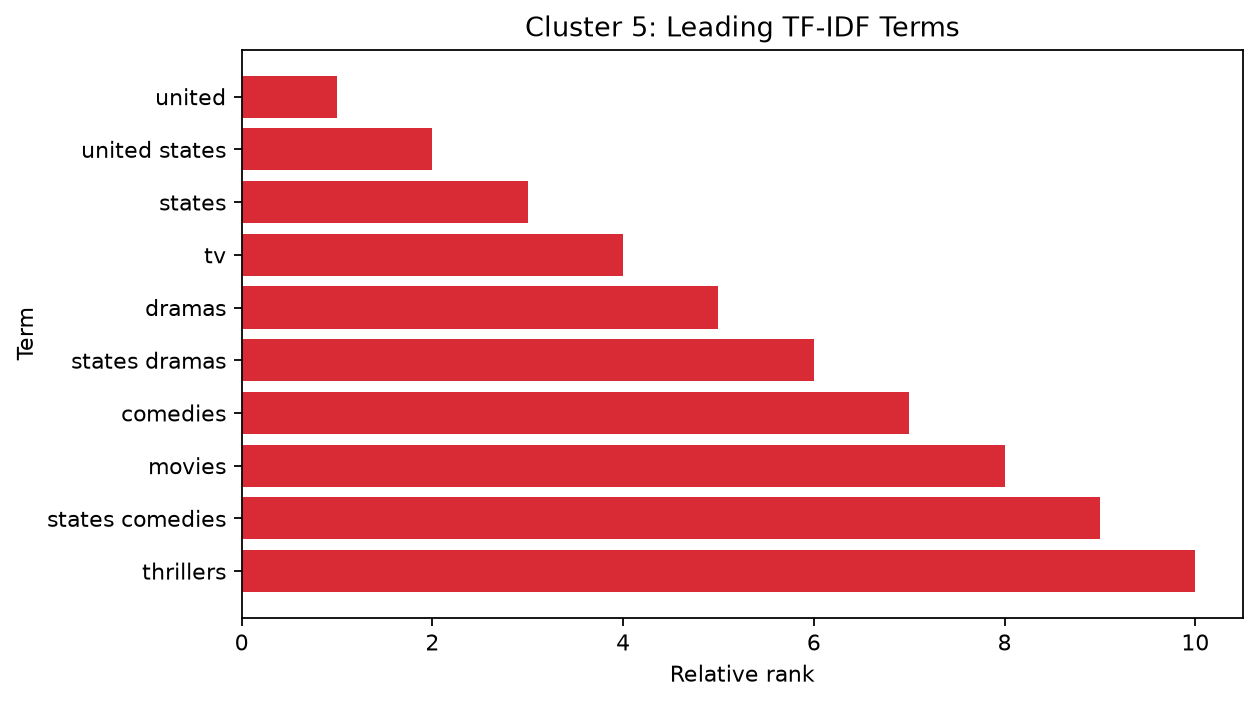


Cluster 6 — TV Show-focused · Kids' TV-led
Size: 406 (5.21%)
Content type share (%): {'TV Show': 99.8, 'Movie': 0.2}
Common countries: ['United States', 'Canada', 'France', 'United Kingdom', 'Japan']
Common ratings: ['TV-Y7', 'TV-Y', 'TV-PG', 'TV-G', 'TV-14']
Common genres: ["Kids' TV", 'TV Comedies', 'British TV Shows', 'Korean TV Shows', 'TV Action & Adventure']
K-Means centroid terms (approximate TF-IDF projection): ['kids', 'kids tv', 'tv', 'tv tv', 'states kids', 'tv comedies', 'adventures', 'friends', 'united', 'united states', 'states', 'series']
Cluster mean TF-IDF terms: ['kids', 'kids tv', 'tv', 'states kids', 'tv tv', 'tv comedies', 'friends', 'adventures', 'united', 'united states', 'states', 'series']
Representative titles: ['The Minimighty Kids', 'Sunny Bunnies', 'Zig & Sharko', 'Trotro', 'Sammy & Co']


,title,description
5366,Sammy & Co,In an underwater village bordering a tropical ...
5885,Sunny Bunnies,Furry little bunnies hop through wild adventur...
6671,The Minimighty Kids,"Some have big feet or a sniffly nose, others a..."
7236,Trotro,"Trotro the donkey may be opinionated, but he's..."
7766,Zig & Sharko,"Zig, an island-bound hyena, will do anything t..."


Characteristics: TV Show-focused; strongest listed category is Kids' TV; terms and example synopses above provide the text evidence.
Business interpretation: Potential use: use this kids' tv-led tv show segment for navigation and acquisition discussions; validate title fit and audience utility before operational use.


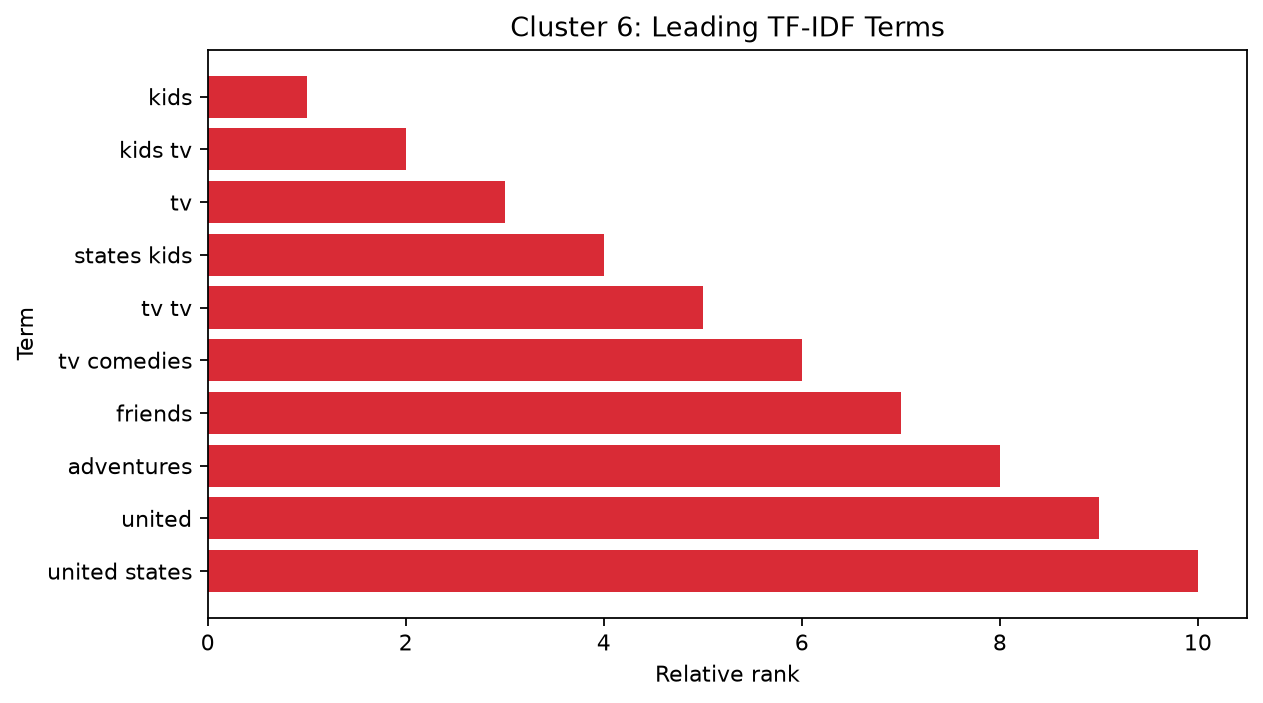


Cluster 7 — TV Show-focused · International TV Shows-led
Size: 1464 (18.80%)
Content type share (%): {'TV Show': 100.0}
Common countries: ['United States', 'United Kingdom', 'Japan', 'South Korea', 'Taiwan']
Common ratings: ['TV-MA', 'TV-14', 'TV-PG', 'TV-G', 'TV-Y7']
Common genres: ['International TV Shows', 'TV Dramas', 'Crime TV Shows', 'Romantic TV Shows', 'TV Comedies']
K-Means centroid terms (approximate TF-IDF projection): ['tv', 'tv shows', 'shows', 'international tv', 'shows tv', 'tv dramas', 'international', 'crime', 'crime tv', 'shows international', 'romantic tv', 'dramas']
Cluster mean TF-IDF terms: ['tv', 'tv shows', 'shows', 'international tv', 'shows tv', 'international', 'tv dramas', 'crime', 'crime tv', 'romantic tv', 'shows international', 'shows romantic']
Representative titles: ['Lovesick', 'Find Yourself', 'Three Wives One Husband', 'Horror Homes', 'Get Even']


,title,description
2168,Find Yourself,A determined entrepreneur navigates a love tri...
2381,Get Even,"In a secret act of skillful revenge, four priv..."
2810,Horror Homes,Dream homes turn into property nightmares when...
3789,Lovesick,Love and academics get complicated at an all-m...
7065,Three Wives One Husband,A film crew captures a year in the life of mod...


Characteristics: TV Show-focused; strongest listed category is International TV Shows; terms and example synopses above provide the text evidence.
Business interpretation: Potential use: use this international tv shows-led tv show segment for navigation and acquisition discussions; validate title fit and audience utility before operational use.


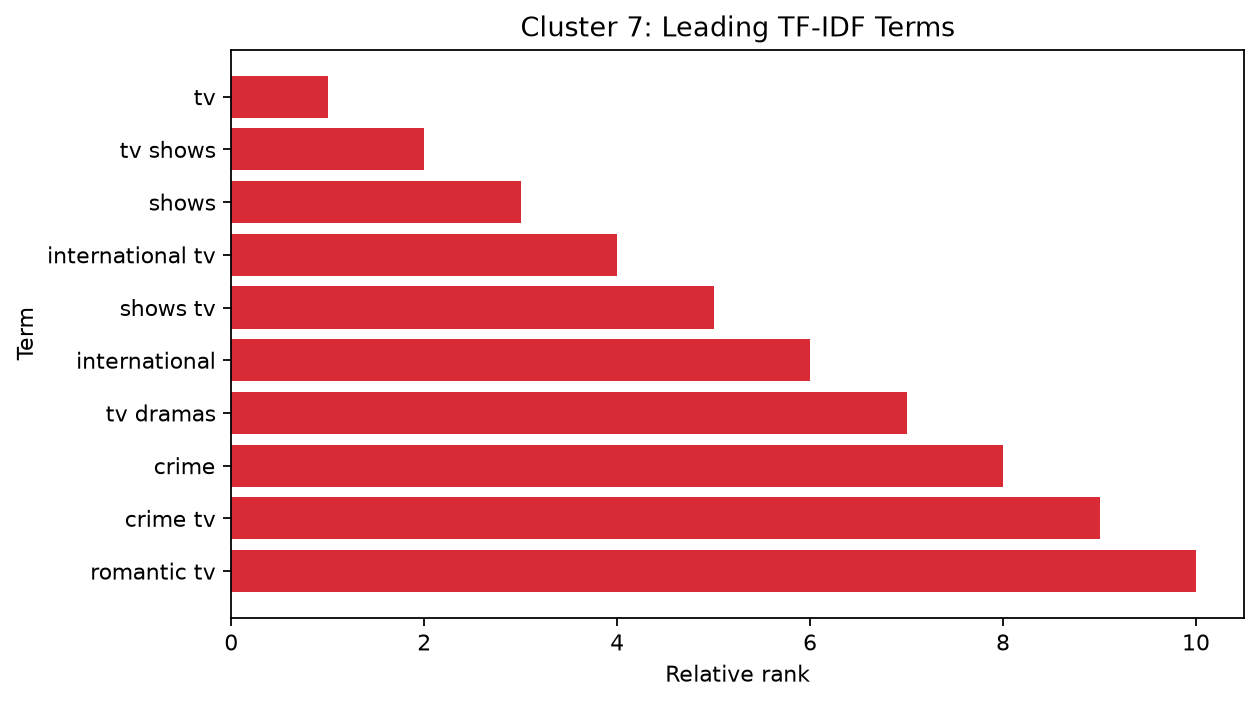


Cluster 8 — Movie-focused · Independent Movies-led
Size: 605 (7.77%)
Content type share (%): {'Movie': 100.0}
Common countries: ['United States', 'India', 'France', 'United Kingdom', 'Canada']
Common ratings: ['TV-MA', 'R', 'TV-14', 'TV-PG', 'PG-13']
Common genres: ['Independent Movies', 'Dramas', 'International Movies', 'Comedies', 'Thrillers']
K-Means centroid terms (approximate TF-IDF projection): ['independent', 'independent movies', 'dramas independent', 'movies', 'movies international', 'dramas', 'states dramas', 'united', 'states', 'united states', 'international movies', 'india']
Cluster mean TF-IDF terms: ['independent movies', 'independent', 'dramas independent', 'movies', 'movies international', 'dramas', 'states dramas', 'united', 'united states', 'states', 'international movies', 'india']
Representative titles: ['WHAT DID JACK DO?', 'Pihu', 'Merku Thodarchi Malai', 'Thithi', 'Inxeba']


,title,description
3045,Inxeba,At an initiation ritual for the young men of h...
4045,Merku Thodarchi Malai,"In southern India, a laborer's dreams of ownin..."
4857,Pihu,A two-year-old must fend for herself when her ...
7052,Thithi,"In a South Indian village, a centenarian's fun..."
7549,WHAT DID JACK DO?,A detective interrogates a monkey who is suspe...


Characteristics: Movie-focused; strongest listed category is Independent Movies; terms and example synopses above provide the text evidence.
Business interpretation: Potential use: use this independent movies-led movie segment for navigation and acquisition discussions; validate title fit and audience utility before operational use.


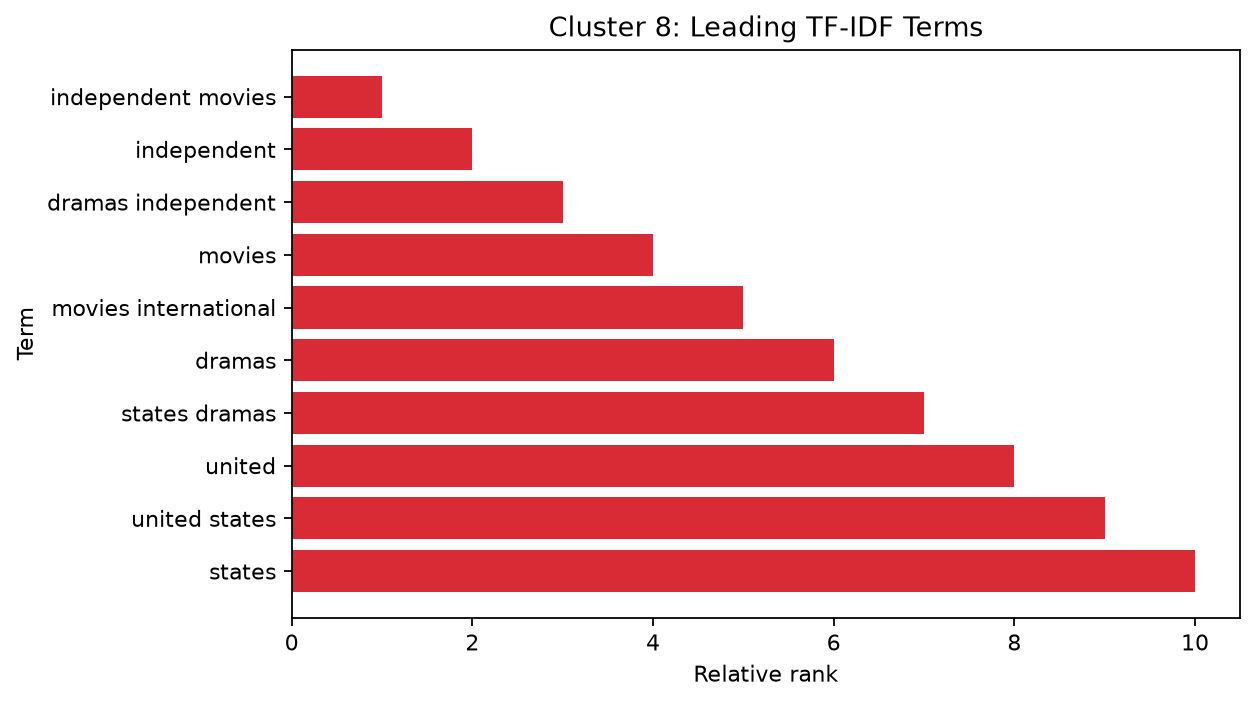

In [24]:
profiles = model_results["profiles"]
def descriptive_cluster_name(profile):
    shares = profile["content_type_share_pct"]
    dominant_type = max(shares, key=shares.get)
    leading_category = profile["common_genres"][0] if profile["common_genres"] else "mixed categories"
    return f"{dominant_type}-focused · {leading_category}-led"

for profile in profiles:
    profile["descriptive_name_after_review"] = descriptive_cluster_name(profile)
    print(f"\nCluster {profile['cluster']} — {profile['descriptive_name_after_review']}")
    print("Size:", profile["size"], f"({profile['percentage']:.2f}%)")
    print("Content type share (%):", profile["content_type_share_pct"])
    print("Common countries:", profile["common_countries"])
    print("Common ratings:", profile["common_ratings"])
    print("Common genres:", profile["common_genres"])
    print("K-Means centroid terms (approximate TF-IDF projection):", profile["kmeans_centroid_terms_approx"])
    print("Cluster mean TF-IDF terms:", profile["important_tfidf_terms"])
    print("Representative titles:", profile["representative_titles"])
    member_rows = featured_df.iloc[np.flatnonzero(labels == profile["cluster"])]
    representative_rows = member_rows.loc[member_rows["title"].isin(profile["representative_titles"]), ["title","description"]]
    display(representative_rows.head(5))
    dominant_type = max(profile["content_type_share_pct"], key=profile["content_type_share_pct"].get)
    category = profile["common_genres"][0] if profile["common_genres"] else "mixed-category"
    profile["business_interpretation"] = f"Potential use: use this {category.lower()}-led {dominant_type.lower()} segment for navigation and acquisition discussions; validate title fit and audience utility before operational use."
    print("Characteristics:", f"{dominant_type}-focused; strongest listed category is {category}; terms and example synopses above provide the text evidence.")
    print("Business interpretation:", profile["business_interpretation"])
    display(Image(filename=str(FIGURES / f"cluster_{profile['cluster']}_top_terms.png")))
with open(TABLES / "cluster_profiles.json", "w", encoding="utf-8") as f:
    json.dump(profiles, f, ensure_ascii=False, indent=2)
pd.DataFrame([{k:v for k,v in p.items() if k != "description_samples"} for p in profiles]).to_csv(TABLES / "cluster_profiles.csv", index=False)

### 25. Model explainability

K-Means assigns a title to the nearest centroid in the reduced SVD space. The notebook shows an approximate inverse-SVD projection of each centroid back to TF-IDF terms, plus average TF-IDF terms across actual assigned members and representative titles nearest to each cluster's mean TF-IDF vector. The explanation is understandable as: a title joins a segment when its weighted words/categories and metadata align with that segment's overall textual profile. The inverse projection is approximate because dimensionality reduction discards information.

Agglomerative clustering joins the closest groups step by step; Ward linkage minimizes increases in within-group squared Euclidean dispersion. The dendrogram summarizes merge distances for the 300-title sample. A high merge distance suggests relatively dissimilar groups being joined, but the tree does not supply semantic names.


### 26. Exceptional case analysis

In [25]:
duration_values = pd.to_numeric(clean_df["duration"].astype("string").str.extract(r"(\d+)")[0], errors="coerce")
movie_dur = duration_values[clean_df["type"].eq("Movie")]
exception_table = pd.DataFrame([
    {"case":"release_year <= 1950", "count":int((clean_df.release_year <= 1950).sum()), "handling":"Retain; likely legitimate catalog/library entries; inspect titles before treating as errors."},
    {"case":"release_year < 1970", "count":int((clean_df.release_year < 1970).sum()), "handling":"Retain; old release year alone is not a data-quality failure."},
    {"case":"Movies under 60 minutes", "count":int((clean_df.type.eq("Movie") & movie_dur.lt(60)).sum()), "handling":"Retain; short films/specials may be valid. Review title-level cases."},
    {"case":"Movies over 180 minutes", "count":int((clean_df.type.eq("Movie") & movie_dur.gt(180)).sum()), "handling":"Retain; long/special-format titles may be legitimate."},
    {"case":"missing director, cast, or country simultaneously", "count":int(clean_df[["director","cast","country"]].isna().all(axis=1).sum()), "handling":"Retain; sparse credits reduce metadata signal but descriptions remain available."},
    {"case":"missing descriptions", "count":int(clean_df.description.isna().sum()), "handling":"None in the supplied CSV; preserve if present."},
    {"case":"rare rating labels (count <= 5)", "count":int(clean_df.rating.value_counts().le(5).sum()), "handling":"Retain rare labels; labels such as NC-17/UR can be uncommon but are not inherently invalid."},
    {"case":"country mentions appearing once", "count":int((clean_df.country.fillna('').str.split(', ').explode().str.strip().value_counts()==1).sum()), "handling":"Retain rare country mentions; uncommon credits may describe legitimate titles."},
])
display(exception_table)
exception_table.to_csv(TABLES / "exceptional_cases.csv", index=False)
print("Movie duration numeric summary (minutes):")
display(movie_dur.describe().to_frame("minutes"))
print("TV Show season counts:")
display(clean_df.loc[clean_df.type.eq("TV Show"), "duration"].value_counts().head(10).to_frame("titles"))
print("Potential edge examples:")
display(clean_df.loc[clean_df.type.eq("Movie") & movie_dur.lt(60), ["title","release_year","duration","description"]].head(10))
print("Oldest listed releases:")
display(clean_df.nsmallest(5, "release_year")[["title","release_year","type","duration"]])
print("Longest Movie durations:")
display(clean_df.loc[clean_df.type.eq("Movie")].assign(duration_minutes=movie_dur).nlargest(5,"duration_minutes")[["title","release_year","duration","description"]])
print("Rare rating categories:")
rare = clean_df["rating"].value_counts()
display(rare[rare.le(10)].to_frame("titles"))

,case,count,handling
0,release_year <= 1950,15,Retain; likely legitimate catalog/library entr...
1,release_year < 1970,51,Retain; old release year alone is not a data-q...
2,Movies under 60 minutes,420,Retain; short films/specials may be valid. Rev...
3,Movies over 180 minutes,38,Retain; long/special-format titles may be legi...
4,"missing director, cast, or country simultaneously",58,Retain; sparse credits reduce metadata signal ...
5,missing descriptions,0,None in the supplied CSV; preserve if present.
6,rare rating labels (count <= 5),2,Retain rare labels; labels such as NC-17/UR ca...
7,country mentions appearing once,39,Retain rare country mentions; uncommon credits...


Movie duration numeric summary (minutes):


,minutes
count,5377.0
mean,99.307978
std,28.530881
min,3.0
25%,86.0
50%,98.0
75%,114.0
max,312.0


TV Show season counts:


,titles
duration,
1 Season,1608
2 Seasons,382
3 Seasons,184
4 Seasons,87
5 Seasons,58
6 Seasons,30
7 Seasons,19
8 Seasons,18
9 Seasons,8


...

,title,release_year,type,duration
4867,Pioneers: First Women Filmmakers*,1925,TV Show,1 Season
4960,Prelude to War,1942,Movie,52 min
6117,The Battle of Midway,1942,Movie,18 min
7342,Undercover: How to Operate Behind Enemy Lines,1943,Movie,61 min
7616,Why We Fight: The Battle of Russia,1943,Movie,82 min


Longest Movie durations:


,title,release_year,duration,description
957,Black Mirror: Bandersnatch,2018,312 min,"In 1984, a young programmer begins to question..."
6850,The School of Mischief,1973,253 min,A high school teacher volunteers to transform ...
4490,No Longer kids,1979,237 min,Hoping to prevent their father from skipping t...
3694,Lock Your Girls In,1982,233 min,A widower believes he must marry off his three...
5108,Raya and Sakina,1984,230 min,When robberies and murders targeting women swe...


Rare rating categories:


,titles
rating,
TV-Y7-FV,6
UR,5
NC-17,3


## 27. Business insights and stakeholder use cases

In [26]:
business_rows = [
    {"Technical Finding":f"{movie_n:,} Movies vs {tv_n:,} TV Shows in this supplied file", "Business Meaning":"Catalog composition is movie-heavy in row count", "Possible Netflix Use":"Format-aware catalog summaries and discovery surfaces"},
    {"Technical Finding":f"H1 date-era chi-square p={hypotheses[0]['p_value']:.4g}; TV shares={hypotheses[0]['direction_values']}", "Business Meaning":"Type mix differs statistically across broad addition eras, but the shares are not monotonic", "Possible Netflix Use":"Use as a prompt for deeper time-series/catalog-history analysis; avoid a simple 'TV increasingly replaced Movies' claim"},
    {"Technical Finding":f"H2 primary-country association p={hypotheses[1]['p_value']:.4g}", "Business Meaning":"Observed type mix varies across first-listed country groups", "Possible Netflix Use":"Explore regional catalog organization, with co-production/missing-data caveats"},
    {"Technical Finding":f"K-Means selected K={selected_k}; sampled cosine silhouette={comparison.iloc[0]['silhouette_cosine']:.3f}", "Business Meaning":"Text segments show some structure but remain overlapping", "Possible Netflix Use":"Use clusters as candidate catalog tags to review, not final personalization decisions"},
    {"Technical Finding":"Documentary, family, kids-TV, stand-up, international and broad drama/TV groups appear in profiles", "Business Meaning":"Some clusters are category/format-led and some are broad", "Possible Netflix Use":"Improve exploratory catalog browsing and inform content-segment discussions"},
    {"Technical Finding":"Text clusters are built from title, credits, country, categories, and synopsis", "Business Meaning":"Similarity reflects available metadata wording, not viewer behavior", "Possible Netflix Use":"Potential preprocessing for future recommender research; not a recommender itself"},
]
business_table = pd.DataFrame(business_rows)
display(business_table)
business_table.to_csv(TABLES / "business_insights.csv", index=False)

,Technical Finding,Business Meaning,Possible Netflix Use
0,"5,377 Movies vs 2,410 TV Shows in this supplie...",Catalog composition is movie-heavy in row count,Format-aware catalog summaries and discovery s...
1,H1 date-era chi-square p=0.04262; TV shares={'...,Type mix differs statistically across broad ad...,Use as a prompt for deeper time-series/catalog...
2,H2 primary-country association p=7.385e-139,Observed type mix varies across first-listed c...,"Explore regional catalog organization, with co..."
3,K-Means selected K=9; sampled cosine silhouett...,Text segments show some structure but remain o...,Use clusters as candidate catalog tags to revi...
4,"Documentary, family, kids-TV, stand-up, intern...",Some clusters are category/format-led and some...,Improve exploratory catalog browsing and infor...
5,"Text clusters are built from title, credits, c...",Similarity reflects available metadata wording...,Potential preprocessing for future recommender...


### 28. Limitations and future scope

**Limitations**

- The supplied file extends to `date_added` in 2021, while the brief frames the data as available by 2019; source-snapshot provenance should be confirmed before making 2019-specific claims.
- `date_added` in this catalog is not a complete record of content acquisition, removals, or commissioning; associations do not establish strategic intent.
- Missing director (30.68%), cast (9.22%), country (6.51%), rating (0.09%), and date-added (0.13%) metadata remain visible. Country/category fields are multi-valued and some analyses use first-listed or exploded counts.
- Clustering is unsupervised; no ground-truth labels or user engagement data are available. Internal scores are modest/overlapping and depend on TF-IDF/SVD/model choices.
- Hierarchical fitting is sampled (1,500 titles; dendrogram uses 300) because of quadratic cost. Agglomerative labels are not full-catalog assignments.
- Text similarity can reflect shared categories, countries, and generic metadata tokens; it does not imply audience preference, quality, or business performance.

**Future scope**

1. Confirm the precise catalog extraction date and use a consistent historical snapshot.
2. Conduct sensitivity analysis across field weighting, min_df, vocabulary size, SVD dimensions, and distance metrics.
3. Ask domain reviewers to assess cluster coherence and usefulness.
4. If approved, enrich with external ratings or market metadata and clearly document source/licensing; avoid turning that into rating prediction unless separately requested.
5. Use engagement data only for a separately scoped evaluation of downstream discovery/recommendation use.


### 29. Final conclusion

In [27]:
best_k_row = k_selection.loc[k_selection.silhouette_sample.idxmax()]
tv_shares = hypotheses[0]["direction_values"]
display(Markdown(
    f"The supplied **{len(clean_df):,}-title** catalog can be represented with sparse TF-IDF and grouped into exploratory text/content segments. "
    f"The stated selection rule chose **K={selected_k}**; the best candidate silhouette in K=2–10 was {best_k_row.silhouette_sample:.3f} at K={int(best_k_row.k)}. "
    f"K-Means and sampled {model_results['selected_linkage']} agglomerative clustering provide complementary partitions; neither is ground truth. "
    f"Observed TV Show shares by addition era were {', '.join(f'{k}: {v:.1%}' for k,v in tv_shares.items())}, so the data do not support a simple monotonic increase claim. "
    "Use the clusters as reviewable catalog-segmentation hypotheses, with source-date and metadata limitations kept visible."
))

The supplied **7,787-title** catalog can be represented with sparse TF-IDF and grouped into exploratory text/content segments. The stated selection rule chose **K=9**; the best candidate silhouette in K=2–10 was 0.178 at K=9. K-Means and sampled ward agglomerative clustering provide complementary partitions; neither is ground truth. Observed TV Show shares by addition era were 2008-2014: 21.1%, 2015-2017: 32.8%, 2018-2021: 30.4%, so the data do not support a simple monotonic increase claim. Use the clusters as reviewable catalog-segmentation hypotheses, with source-date and metadata limitations kept visible.

## Stage 7 — Storytelling & Video Presentation

### 30. Video narrative: WHY → WHAT → HOW → RESULT → BUSINESS IMPACT

Do not read code. Show the supplied catalog, selected charts, model-selection evidence, cluster examples, and limitations. The timed plan below totals 10 minutes 30 seconds, meeting the deck's requirement for a video longer than 7 minutes and within the stated approximate 20–30 minute maximum.


In [28]:
video_plan = pd.DataFrame([
    ("0:00–0:30", "Introduction", "Set up the question: how can a large catalog be explored through content similarity?", "Title slide"),
    ("0:30–1:00", "Business context", "Explain catalog discovery and segmentation; clarify this is not a recommendation engine.", "Business-context slide"),
    ("1:00–1:30", "Problem and objectives", "State the clustering question and why labels are unavailable.", "Problem/objectives"),
    ("1:30–2:00", "Dataset and scope", f"Report {len(clean_df):,} records, 12 observed columns, and date-added range {added.min():%Y}–{added.max():%Y}; flag the 2019-brief vs 2021-file mismatch.", "Schema and data dictionary"),
    ("2:00–2:40", "Cleaning", "Explain preserved missing metadata, zero exact duplicates, whitespace normalization, and retained unusual titles.", "Missingness/cleaning impact table"),
    ("2:40–3:45", "EDA discoveries", f"Show type mix ({movie_n:,} Movies; {tv_n:,} TV Shows), add-year and release-year trends, ratings, country/type heatmap, genres, and duration.", "EDA charts"),
    ("3:45–4:30", "Hypothesis testing", f"Explain chi-square and Mann–Whitney results. Highlight non-monotonic TV shares across eras: {tv_shares}.", "Hypothesis results table"),
    ("4:30–5:20", "Feature engineering and TF-IDF", "Describe combined fields, conservative text cleaning, TF-IDF vs counts, sparse vectors, and 100-component SVD.", "Feature flow / matrix summary"),
    ("5:20–6:20", "K-Means and K selection", f"Show elbow and silhouette evidence; explain the 1% tie rule and selected K={selected_k}.", "Elbow/silhouette charts"),
    ("6:20–7:10", "Agglomerative clustering", f"Explain Ward/average linkage sample comparison, selected {model_results['selected_linkage']} with {model_results['hierarchy_k']} groups, and sampled dendrogram.", "Dendrogram"),
    ("7:10–8:20", "Evaluation and clusters", f"Compare silhouette ({comparison.iloc[0]['silhouette_cosine']:.3f} vs {comparison.iloc[1]['silhouette_cosine']:.3f}) and show cluster sizes, terms, and representative titles.", "Metrics, cluster map, profiles"),
    ("8:20–9:10", "Business use", "Present clusters as catalog organization hypotheses and possible future recommender preprocessing; ask stakeholders to validate.", "Technical-to-business table"),
    ("9:10–9:50", "Limitations and future scope", "Mention provenance mismatch, missing fields, internal metrics, metadata-driven similarity, and sampled hierarchy.", "Limitations slide"),
    ("9:50–10:30", "Conclusion", "Restate what was learned, what clusters can support, and what evidence is needed before operational use.", "Closing slide"),
], columns=["time","section","speaking_points","visuals_to_show"])
display(video_plan)
video_plan.to_csv(TABLES / "video_presentation_plan.csv", index=False)

,time,section,speaking_points,visuals_to_show
0,0:00–0:30,Introduction,Set up the question: how can a large catalog b...,Title slide
1,0:30–1:00,Business context,Explain catalog discovery and segmentation; cl...,Business-context slide
2,1:00–1:30,Problem and objectives,State the clustering question and why labels a...,Problem/objectives
3,1:30–2:00,Dataset and scope,"Report 7,787 records, 12 observed columns, and...",Schema and data dictionary
4,2:00–2:40,Cleaning,"Explain preserved missing metadata, zero exact...",Missingness/cleaning impact table
5,2:40–3:45,EDA discoveries,"Show type mix (5,377 Movies; 2,410 TV Shows), ...",EDA charts
6,3:45–4:30,Hypothesis testing,Explain chi-square and Mann–Whitney results. H...,Hypothesis results table
7,4:30–5:20,Feature engineering and TF-IDF,"Describe combined fields, conservative text cl...",Feature flow / matrix summary
8,5:20–6:20,K-Means and K selection,Show elbow and silhouette evidence; explain th...,Elbow/silhouette charts
9,6:20–7:10,Agglomerative clustering,Explain Ward/average linkage sample comparison...,Dendrogram


### 31. Presentation delivery checklist

- Keep the video between **more than 7 minutes** and the deck's stated approximate **20–30 minute maximum**; this plan is about 10½ minutes.
- Explain each chart with: **what we see, why it matters, what we learned**.
- Explain each algorithm with: **why it was used, how the grouping count/linkage was selected, what segments indicate, and how a stakeholder may review them**.
- Use plain language, readable plots, and restrained business claims. The deck requests a notebook and video in a Drive folder with access for everyone; submission dates stated in the deck are 12 Oct 2026 for the two deliverables and 23 Oct 2026 for the Google Form. Confirm logistics with the course organizer.
- A separate ML submission template is mentioned in the deck but was not included with the supplied files; this notebook follows the deck's evaluation criteria and can be transferred into that template when provided.


### 32. Output files and reproducibility

In [29]:
print("Clean data:", "data/processed/netflix_titles_cleaned.csv")
print("Figures:", "outputs/figures")
print("Tables:", "outputs/tables")
print("Models:", "outputs/models")
runtime_versions = model_results["runtime_versions"]
print("Actual runtime versions:", runtime_versions)
display(pd.DataFrame([runtime_versions], index=["version"]).T.rename_axis("package", axis=0).rename(columns={"version":"actual version"}))

Clean data: data/processed/netflix_titles_cleaned.csv
Figures: outputs/figures
Tables: outputs/tables
Models: outputs/models
Actual runtime versions: {'python': '3.14.6', 'pandas': '3.0.5', 'numpy': '2.5.3', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.1', 'seaborn': '0.13.2', 'joblib': '1.6.0'}


,actual version
package,
python,3.14.6
pandas,3.0.5
numpy,2.5.3
scikit-learn,1.9.1
matplotlib,3.11.1
seaborn,0.13.2
joblib,1.6.0


### 33. Video presentation summary

The presentation opens with the business need for catalog discovery, demonstrates the actual supplied-data findings, explains the TF-IDF/SVD clustering choices with measured K and internal metrics, then interprets representative segments and their limits. It ends with practical stakeholder review questions rather than unsupported performance claims.